# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
import pandas as pd

clients = pd.read_csv(
    "clients.csv",
    encoding="utf-8",
    sep=",",
    dtype={"client_id": "string", "branch_code": "string"},
)

transactions = pd.read_csv(
    "transactions.csv",
    encoding="cp1251",
    sep=";",
    decimal=",",
    dtype={"client_id": "string", "txn_id": "string", "mcc_code": "string"},
)

display(clients.head())
display(transactions.head())

print(clients.shape, transactions.shape)
clients.info()
transactions.info()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C002200,1954-09-17,Ж,Новосибирск,Массовый,Серебро,Кредитная,29.11.2019,06.05.2025,Зарплата в другом банке,-999.0,Нет,NaN,NaN,00398,Нет
1,C003749,1964-06-21,Ж,г.Екатеринбург,Зарплатный,Базовый,Кредитная,28.06.2019,28.05.2021,Зарплата в нашем банке,66800.0,Да,2024-09,3.0,00238,Да
2,C002879,1965-04-20,Ж,Санкт-Петербург,Private,Платина,Премиальная,21.04.2020,22.06.2020,Зарплата в другом банке,352100.0,Нет,NaN,4.0,00540,Нет
3,C000991,1981-03-06,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,22.07.2022,01.07.2024,Не указан,NaN,Да,2024-01,NaN,00302,Да
4,C002710,1988-01-19,Ж,Казань,Зарплатный,Серебро,Дебетовая,02.12.2015,20.03.2019,Зарплата в нашем банке,41200.0,Да,2024-07,2.0,00774,Да


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990027,C000538,2023-11-29 23:56:29,1196.47,RUB,Продукты,5411,Токен,успешно
1,990023,C003855,2023-12-02 15:20:42,1196.67,RUB,кафе и рестораны,5812,Карта,успешно
2,990110,C000361,2023-12-09 09:27:07,514.51,RUB,Аптеки,5912,СБП,успешно
3,990151,C004853,2023-12-11 06:57:40,222.20,RUB,Аптеки,5912,Карта,успешно
4,990150,C004233,2023-12-25 10:33:33,2918.42,RUB,Кафе/рестораны,5812,Карта,успешно


(5695, 16) (617861, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5695 entries, 0 to 5694
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5695 non-null   string 
 1   birth_date          5695 non-null   object 
 2   gender              5695 non-null   object 
 3   city                5695 non-null   object 
 4   segment             5695 non-null   object 
 5   loyalty_tier        5695 non-null   object 
 6   card_type           5695 non-null   object 
 7   registration_date   5695 non-null   object 
 8   card_open_date      5695 non-null   object 
 9   income_source       5695 non-null   object 
 10  monthly_income      5176 non-null   float64
 11  has_mobile_app      5695 non-null   object 
 12  app_last_login      3543 non-null   object 
 13  satisfaction_score  2283 non-null   float64
 14  branch_code         5695 non-null   string 
 15  marketing_opt_in    5695 non-nul

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [3]:
print("Строк в clients: ", len(clients))
print("Уникальных client_id: ", clients["client_id"].nunique())
print("Пропусков в client_id: ", clients["client_id"].isna().sum())
print("Повторных значений client_id: ", clients["client_id"].duplicated().sum())

print()

print("Строк в transactions: ", len(transactions))
print("Уникальных txn_id: ", transactions["txn_id"].nunique())
print("Пропусков в txn_id: ", transactions["txn_id"].isna().sum())
print("Повторных значений txn_id: ", transactions["txn_id"].duplicated().sum())

Строк в clients:  5695
Уникальных client_id:  5640
Пропусков в client_id:  0
Повторных значений client_id:  55

Строк в transactions:  617861
Уникальных txn_id:  616361
Пропусков в txn_id:  0
Повторных значений txn_id:  1500


In [4]:
missing = pd.DataFrame({
    "число пропусков": clients.isna().sum(),
    "доля, %": clients.isna().mean() * 100,
})

display(missing[missing["число пропусков"] > 0])

,число пропусков,"доля, %"
monthly_income,519,9.113257
app_last_login,2152,37.787533
satisfaction_score,3412,59.912204


### 2.2. Дубли

In [5]:
print("Полных дублей в clients: ", clients.duplicated().sum())
print("Полных дублей в transactions: ", transactions.duplicated().sum())

Полных дублей в clients:  40
Полных дублей в transactions:  1275


In [6]:
clients_unique_rows = clients.drop_duplicates()

client_conflicts = clients_unique_rows[
    clients_unique_rows["client_id"].duplicated(keep=False)
].sort_values("client_id")

print("Строк с повторяющимся client_id:", len(client_conflicts))
print("Разных повторяющихся client_id:",
      client_conflicts["client_id"].nunique())

display(client_conflicts.head(10))

Строк с повторяющимся client_id: 30
Разных повторяющихся client_id: 15


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
2683,C001177,1975-02-21,Ж,Казань,Private,Базовый,Дебетовая,11.12.2011,13.06.2016,Не указан,55700.0,Да,2025-05,4.0,00361,Да
2094,C001177,1975-02-21,Ж,Новосибирск,Массовый,Базовый,Дебетовая,11.12.2011,13.06.2016,Не указан,55700.0,Да,2025-05,4.0,00361,Да
4971,C001384,1960-04-14,Ж,Новосибирск,Массовый,Базовый,Дебетовая,12.02.2019,08.11.2019,Не указан,38700.0,Да,2024-08,NaN,00275,Да
704,C001384,1960-04-14,Ж,Москва,Private,Базовый,Дебетовая,12.02.2019,08.11.2019,Не указан,38700.0,Да,2024-08,NaN,00275,Да
3950,C001580,1974-12-13,М,Екатеринбург,Премиальный,Золото,Дебетовая,18.01.2015,25.09.2020,Зарплата в нашем банке,132500.0,Да,2024-01,5.0,00408,Да
2142,C001580,1974-12-13,М,Москва,Зарплатный,Золото,Дебетовая,18.01.2015,25.09.2020,Зарплата в нашем банке,132500.0,Да,2024-01,5.0,00408,Да
1200,C002248,1989-08-18,М,Казань,Массовый,Базовый,Дебетовая,17.12.2022,24.07.2024,Зарплата в нашем банке,140500.0,Да,2024-10,2.0,00518,Да
2150,C002248,1989-08-18,М,Москва,Зарплатный,Базовый,Дебетовая,17.12.2022,24.07.2024,Зарплата в нашем банке,140500.0,Да,2024-10,2.0,00518,Да
988,C002533,1971-11-14,Ж,Екатеринбург,Премиальный,Золото,Кредитная,15.12.2022,25.04.2025,Зарплата в другом банке,282.4,Нет,NaN,2.0,00737,Да
3196,C002533,1971-11-14,Ж,г. Новосибирск,Премиальный,Золото,Кредитная,15.12.2022,25.04.2025,Зарплата в другом банке,282.4,Нет,NaN,2.0,00737,Да


In [7]:
transactions_unique_rows = transactions.drop_duplicates()

txn_conflicts = transactions_unique_rows[
    transactions_unique_rows["txn_id"].duplicated(keep=False)
].sort_values("txn_id")

print("Строк с повторяющимся txn_id:", len(txn_conflicts))
print("Разных повторяющихся txn_id:",
      txn_conflicts["txn_id"].nunique())

display(txn_conflicts.head(10))

Строк с повторяющимся txn_id: 450
Разных повторяющихся txn_id: 225


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
1357,101349,C004453,2024-01-03,9845.61,RUB,Одежда и обувь,5651,Карта,успешно
1358,101349,C004453,2024-01-03 05:12:35,9845.61,RUB,Одежда и обувь,5651,Карта,успешно
3567,103551,C000535,2024-01-05,-65.47,RUB,Транспорт,4111,СБП,возврат
3568,103551,C000535,2024-01-05 14:52:37,-65.47,RUB,Транспорт,4111,СБП,возврат
4732,104712,C005015,2024-01-06 12:26:03,1593.47,RUB,Кафе и рестораны,5812,Карта,успешно
4733,104712,C005015,2024-01-06,1593.47,RUB,Кафе и рестораны,5812,Карта,успешно
8695,108671,C000944,2024-01-10 15:54:54,958.61,RUB,Связь и Интернет,4814,СБП,успешно
8696,108671,C000944,2024-01-10,958.61,RUB,Связь и Интернет,4814,СБП,успешно
10069,110039,C001254,2024-01-12 15:25:05,872.85,RUB,АЗС,5541,СБП,успешно
10070,110039,C001254,2024-01-12,872.85,RUB,АЗС,5541,СБП,успешно


In [8]:
client_differences = (
    client_conflicts
    .groupby("client_id")
    .nunique(dropna=False)
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)

display(client_differences[client_differences > 0])

city       14
segment    11
dtype: int64

In [9]:
txn_differences = (
    txn_conflicts
    .groupby("txn_id")
    .nunique(dropna=False)
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)

display(txn_differences[txn_differences > 0])

txn_datetime    225
dtype: int64

In [10]:
txn_check = txn_conflicts.copy()

dates = txn_check["txn_datetime"].astype("string").str.strip()

txn_check["only_date"] = dates.str.fullmatch(
    r"\d{4}-\d{2}-\d{2}", na=False
)

txn_check["has_time"] = dates.str.fullmatch(
    r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}", na=False
)

txn_check["day"] = pd.to_datetime(
    dates.str.slice(0, 10),
    format="%Y-%m-%d",
    errors="coerce"
)

full_datetime = pd.to_datetime(
    dates.where(txn_check["has_time"]),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

txn_check["valid_date_only"] = (
    txn_check["only_date"] & txn_check["day"].notna()
)
txn_check["valid_full_datetime"] = (
    txn_check["has_time"] & full_datetime.notna()
)

txn_pair_check = txn_check.groupby("txn_id").agg(
    rows=("txn_id", "size"),
    distinct_days=("day", "nunique"),
    valid_date_only=("valid_date_only", "sum"),
    valid_full_datetime=("valid_full_datetime", "sum"),
)

matches_pattern = (
    (txn_pair_check["rows"] == 2)
    & (txn_pair_check["distinct_days"] == 1)
    & (txn_pair_check["valid_date_only"] == 1)
    & (txn_pair_check["valid_full_datetime"] == 1)
)

print("Всего конфликтующих txn_id:", len(txn_pair_check))
print("Соответствуют ожидаемому шаблону:", matches_pattern.sum())
print("Требуют отдельного изучения:", (~matches_pattern).sum())

display(txn_pair_check[~matches_pattern].head(10))

Всего конфликтующих txn_id: 225
Соответствуют ожидаемому шаблону: 225
Требуют отдельного изучения: 0


,rows,distinct_days,valid_date_only,valid_full_datetime
txn_id,,,,


### 2.3. Соответствие данных описанию полей из задания

In [11]:
client_columns = [
    "gender",
    "city",
    "segment",
    "loyalty_tier",
    "card_type",
    "income_source",
    "has_mobile_app",
    "marketing_opt_in",
]

for column in client_columns:
    print(f"\n--- {column} ---")
    print(clients[column].value_counts(dropna=False))


--- gender ---
gender
М    2854
Ж    2841
Name: count, dtype: int64

--- city ---
city
Москва                1088
Новосибирск            709
Санкт-Петербург        657
Нижний Новгород        566
Казань                 553
Екатеринбург           502
г. Новосибирск         223
казань                 193
 москва                187
г. Москва              180
Н. Новгород            163
МОСКВА                 158
г.Екатеринбург         123
г. Санкт-Петербург     112
ЕКАТЕРИНБУРГ            96
СПб                     94
Санкт Петербург         91
Name: count, dtype: int64

--- segment ---
segment
Массовый       2908
Зарплатный     1649
Премиальный     884
Private         254
Name: count, dtype: int64

--- loyalty_tier ---
loyalty_tier
Базовый    2861
Серебро    1536
Золото      981
Платина     317
Name: count, dtype: int64

--- card_type ---
card_type
Дебетовая      3937
Кредитная      1258
Премиальная     500
Name: count, dtype: int64

--- income_source ---
income_source
Зарплата в нашем ба

In [12]:
transaction_columns = [
    "currency",
    "category",
    "channel",
    "status",
]

for column in transaction_columns:
    print(f"\n--- {column} ---")
    print(transactions[column].value_counts(dropna=False))


--- currency ---
currency
RUB    615367
EUR      1269
USD      1225
Name: count, dtype: int64

--- category ---
category
Продукты               163176
Транспорт               71341
Одежда и обувь          63623
АЗС                     56567
Кафе и рестораны        47695
Развлечения и досуг     46700
Аптеки                  44970
Онлайн-сервисы          42987
Связь и интернет        29358
Связь и Интернет        19311
Кафе/рестораны          16207
кафе и рестораны        15926
Name: count, dtype: int64

--- channel ---
channel
Карта          318142
СБП            109927
Токен          101914
Онлайн-банк     87878
Name: count, dtype: int64

--- status ---
status
успешно      598319
отклонено     12091
возврат        7451
Name: count, dtype: int64


In [13]:
print("Значения оценки и их частота:")
print(clients["satisfaction_score"].value_counts(dropna=False).sort_index())

score = clients["satisfaction_score"]

outside_range = score.notna() & ~score.between(1, 5)
not_integer = score.notna() & (score % 1 != 0)

print("\nНепустых оценок вне диапазона 1–5:", outside_range.sum())
print("Непустых нецелых оценок:", not_integer.sum())

Значения оценки и их частота:
satisfaction_score
1.0     307
2.0     453
3.0     475
4.0     444
5.0     604
NaN    3412
Name: count, dtype: int64

Непустых оценок вне диапазона 1–5: 0
Непустых нецелых оценок: 0


In [14]:
income = clients["monthly_income"]

print("Сводка по непустым значениям:")
print(income.describe())

print("\nОтрицательных значений:", (income < 0).sum())
print("Значений -999:", (income == -999).sum())
print("Нулевых значений:", (income == 0).sum())

Сводка по непустым значениям:
count      5176.000000
mean      96051.514065
std       85088.756119
min        -999.000000
25%       51600.000000
50%       73500.000000
75%      108700.000000
max      815500.000000
Name: monthly_income, dtype: float64

Отрицательных значений: 47
Значений -999: 47
Нулевых значений: 0


In [15]:
category_for_check = transactions["category"].replace({
    "Кафе/рестораны": "Кафе и рестораны",
    "кафе и рестораны": "Кафе и рестораны",
    "Связь и Интернет": "Связь и интернет",
})

print("Число категорий после временного объединения написаний:",
      category_for_check.nunique())

category_mcc = pd.DataFrame({
    "mcc_code": transactions["mcc_code"],
    "category": category_for_check,
})

mcc_category_counts = (
    category_mcc.groupby("mcc_code", dropna=False)["category"]
    .nunique(dropna=False)
    .sort_values(ascending=False)
)

print("\nMCC, связанные более чем с одной категорией:")
display(mcc_category_counts[mcc_category_counts > 1])

Число категорий после временного объединения написаний: 9

MCC, связанные более чем с одной категорией:


mcc_code
4111    9
4814    9
5411    9
5541    9
5651    9
5812    9
5815    9
5912    9
7832    9
Name: category, dtype: int64

In [16]:
amount_check = pd.DataFrame({
    "status": transactions["status"],
    "negative": transactions["amount"] < 0,
    "zero": transactions["amount"] == 0,
    "positive": transactions["amount"] > 0,
    "missing": transactions["amount"].isna(),
})

display(
    amount_check.groupby("status", dropna=False)[
        ["negative", "zero", "positive", "missing"]
    ].sum()
)

,negative,zero,positive,missing
status,,,,
возврат,7451,0,0,0
отклонено,0,0,12091,0
успешно,0,0,598319,0


In [17]:
category_mcc_counts = pd.crosstab(
    category_for_check,
    transactions["mcc_code"]
)

display(category_mcc_counts)

category_mcc_percent = (
    category_mcc_counts
    .div(category_mcc_counts.sum(axis=0), axis=1)
    .mul(100)
    .round(2)
)

display(category_mcc_percent)

mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,41,17,23,56374,22,26,26,20,18
Аптеки,13,15,13,16,14,12,21,44846,20
Кафе и рестораны,23,24,45,34,28,79579,28,39,28
Одежда и обувь,29,19,17,26,63456,23,14,15,24
Онлайн-сервисы,12,19,12,12,16,14,42872,13,17
Продукты,57,53,162755,50,49,61,57,51,43
Развлечения и досуг,10,16,13,25,23,16,18,15,46564
Связь и интернет,17,48526,13,18,19,16,25,15,20
Транспорт,71148,24,28,18,25,20,24,21,33


mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,0.06,0.03,0.01,99.65,0.03,0.03,0.06,0.04,0.04
Аптеки,0.02,0.03,0.01,0.03,0.02,0.02,0.05,99.58,0.04
Кафе и рестораны,0.03,0.05,0.03,0.06,0.04,99.76,0.06,0.09,0.06
Одежда и обувь,0.04,0.04,0.01,0.05,99.69,0.03,0.03,0.03,0.05
Онлайн-сервисы,0.02,0.04,0.01,0.02,0.03,0.02,99.51,0.03,0.04
Продукты,0.08,0.11,99.90,0.09,0.08,0.08,0.13,0.11,0.09
Развлечения и досуг,0.01,0.03,0.01,0.04,0.04,0.02,0.04,0.03,99.57
Связь и интернет,0.02,99.62,0.01,0.03,0.03,0.02,0.06,0.03,0.04
Транспорт,99.72,0.05,0.02,0.03,0.04,0.03,0.06,0.05,0.07


In [18]:
dominant_category = category_mcc_counts.idxmax(axis=0)

print("Наиболее частая категория для каждого MCC:")
display(dominant_category)

expected_by_mcc = transactions["mcc_code"].map(dominant_category)

comparable = category_for_check.notna() & expected_by_mcc.notna()

mismatch = (
    comparable & category_for_check.ne(expected_by_mcc)
).fillna(False)

print("Строк, которые удалось сравнить:", comparable.sum())
print("Строк с расхождением:", mismatch.sum())

if comparable.sum() > 0:
    print(
        "Доля расхождений среди сравнимых строк:",
        round(mismatch.sum() / comparable.sum() * 100, 2),
        "%"
    )

print("Строк без возможности сравнения:", (~comparable).sum())

Наиболее частая категория для каждого MCC:


mcc_code
4111              Транспорт
4814       Связь и интернет
5411               Продукты
5541                    АЗС
5651         Одежда и обувь
5812       Кафе и рестораны
5815         Онлайн-сервисы
5912                 Аптеки
7832    Развлечения и досуг
dtype: object

Строк, которые удалось сравнить: 617861
Строк с расхождением: 1741
Доля расхождений среди сравнимых строк: 0.28 %
Строк без возможности сравнения: 0


In [19]:
mismatch_by_status = pd.DataFrame({
    "status": transactions["status"],
    "mismatch": mismatch,
}).groupby("status", dropna=False).agg(
    all_rows=("mismatch", "size"),
    mismatch_rows=("mismatch", "sum"),
)

mismatch_by_status["mismatch_share_%"] = (
    mismatch_by_status["mismatch_rows"]
    / mismatch_by_status["all_rows"]
    * 100
).round(2)

display(mismatch_by_status)

,all_rows,mismatch_rows,mismatch_share_%
status,,,
возврат,7451,22,0.30
отклонено,12091,30,0.25
успешно,598319,1689,0.28


In [20]:
birth = pd.to_datetime(
    clients["birth_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

registration = pd.to_datetime(
    clients["registration_date"],
    format="%d.%m.%Y",
    errors="coerce"
)

card_open = pd.to_datetime(
    clients["card_open_date"],
    format="%d.%m.%Y",
    errors="coerce"
)

app_login = pd.to_datetime(
    clients["app_last_login"],
    format="%Y-%m",
    errors="coerce"
)

date_fields = {
    "birth_date": birth,
    "registration_date": registration,
    "card_open_date": card_open,
    "app_last_login": app_login,
}

for column, parsed in date_fields.items():
    original_missing = clients[column].isna().sum()
    parse_failed = (clients[column].notna() & parsed.isna()).sum()

    print(
        column,
        "| исходных пропусков:", original_missing,
        "| непустых значений, не прочитанных в выбранном формате:",
        parse_failed
    )

birth_date | исходных пропусков: 0 | непустых значений, не прочитанных в выбранном формате: 0
registration_date | исходных пропусков: 0 | непустых значений, не прочитанных в выбранном формате: 0
card_open_date | исходных пропусков: 0 | непустых значений, не прочитанных в выбранном формате: 0
app_last_login | исходных пропусков: 2152 | непустых значений, не прочитанных в выбранном формате: 0


In [21]:
snapshot_date = pd.Timestamp("2025-06-30")

print("Дата рождения после даты среза:",
      (birth > snapshot_date).sum())

print("Дата регистрации после даты среза:",
      (registration > snapshot_date).sum())

print("Дата открытия карты после даты среза:",
      (card_open > snapshot_date).sum())

print("Регистрация раньше даты рождения:",
      (registration < birth).sum())

print("Открытие карты раньше регистрации:",
      (card_open < registration).sum())

print("Месяц последнего входа после июня 2025:",
      (app_login >= "2025-07-01").sum())

Дата рождения после даты среза: 0
Дата регистрации после даты среза: 0
Дата открытия карты после даты среза: 0
Регистрация раньше даты рождения: 0
Открытие карты раньше регистрации: 0
Месяц последнего входа после июня 2025: 0


In [22]:
transaction_missing_raw = pd.DataFrame({
    "число пропусков": transactions.isna().sum(),
    "доля, %": transactions.isna().mean() * 100,
})

display(transaction_missing_raw)

,число пропусков,"доля, %"
txn_id,0,0.0
client_id,0,0.0
txn_datetime,0,0.0
amount,0,0.0
currency,0,0.0
category,0,0.0
mcc_code,0,0.0
channel,0,0.0
status,0,0.0


### 2.4. Связь между таблицами

In [23]:
client_ids = set(clients["client_id"].dropna())
transaction_client_ids = set(transactions["client_id"].dropna())

unmatched_transactions = transactions[
    ~transactions["client_id"].isin(client_ids)
]

clients_without_transactions = client_ids - transaction_client_ids

print("Строк операций без клиента в справочнике:",
      len(unmatched_transactions))

print("Разных client_id в таких операциях:",
      unmatched_transactions["client_id"].nunique())

print("Уникальных клиентов без операций:",
      len(clients_without_transactions))

Строк операций без клиента в справочнике: 30019
Разных client_id в таких операциях: 360
Уникальных клиентов без операций: 7


In [24]:
app_missing = pd.crosstab(
    clients["has_mobile_app"],
    clients["app_last_login"].isna(),
    margins=True
)

app_missing.columns = [
    "Дата входа есть",
    "Дата входа пропущена",
    "Всего строк"
]

display(app_missing)

,Дата входа есть,Дата входа пропущена,Всего строк
has_mobile_app,,,
Да,3543,0,3543
Нет,0,2152,2152
All,3543,2152,5695


In [25]:
txn_day = pd.to_datetime(
    transactions["txn_datetime"].astype("string").str.slice(0, 10),
    format="%Y-%m-%d",
    errors="coerce"
)

in_base = (
    (txn_day >= "2024-01-01") &
    (txn_day < "2025-01-01")
)

in_current = (
    (txn_day >= "2025-01-01") &
    (txn_day < "2025-07-01")
)

before_period = txn_day < "2024-01-01"
after_period = txn_day >= "2025-07-01"
unmatched = ~transactions["client_id"].isin(client_ids)

print("Некорректных или пропущенных дат:", txn_day.isna().sum())
print("До 2024 года:", before_period.sum())
print("В 2024 году:", in_base.sum())
print("В январе–июне 2025 года:", in_current.sum())
print("С 1 июля 2025 года:", after_period.sum())

print()
print("Несвязанных строк в 2024 году:",
      (unmatched & in_base).sum())
print("Несвязанных строк в январе–июне 2025 года:",
      (unmatched & in_current).sum())

print()
print("Пропусков client_id в операциях:",
      transactions["client_id"].isna().sum())

Некорректных или пропущенных дат: 0
До 2024 года: 7
В 2024 году: 442890
В январе–июне 2025 года: 174877
С 1 июля 2025 года: 87

Несвязанных строк в 2024 году: 28026
Несвязанных строк в январе–июне 2025 года: 1986

Пропусков client_id в операциях: 0


In [26]:
in_analysis_period = in_base | in_current

monthly_check = pd.DataFrame({
    "month": txn_day.dt.to_period("M"),
    "is_unmatched": unmatched,
    "unmatched_client_id": transactions["client_id"].where(unmatched),
})

monthly_check = monthly_check.loc[in_analysis_period]

monthly_summary = monthly_check.groupby("month").agg(
    all_rows=("is_unmatched", "size"),
    unmatched_rows=("is_unmatched", "sum"),
    unmatched_client_ids=("unmatched_client_id", "nunique"),
)

monthly_summary["unmatched_share_%"] = (
    monthly_summary["unmatched_rows"]
    / monthly_summary["all_rows"]
    * 100
).round(2)

display(monthly_summary)

,all_rows,unmatched_rows,unmatched_client_ids,unmatched_share_%
month,,,,
2024-01,26512,1694,345,6.39
2024-02,32864,2124,349,6.46
2024-03,37970,2465,354,6.49
2024-04,37072,2536,354,6.84
2024-05,33822,2309,355,6.83
2024-06,36615,2467,350,6.74
2024-07,38297,2477,354,6.47
2024-08,38955,2544,358,6.53
2024-09,37300,2451,355,6.57


In [27]:
client_row_counts = clients["client_id"].value_counts()

matches_per_transaction = (
    transactions["client_id"]
    .map(client_row_counts)
    .fillna(0)
)

affected_transactions = (matches_per_transaction > 1).sum()

extra_join_rows = (matches_per_transaction - 1).clip(lower=0).sum()

print(
    "Строк операций с несколькими совпадениями в clients:",
    affected_transactions
)
print(
    "Дополнительных строк при левом соединении сырых таблиц:",
    int(extra_join_rows)
)

Строк операций с несколькими совпадениями в clients: 5071
Дополнительных строк при левом соединении сырых таблиц: 5071


Аудит проведен на сырых данных: таблица клиентов содержит - 5695 строк, таблица операций - 617861 строку. 

Ключи и дубли. В справочнике найдено 5640 уникальных client_id: 40 строк являются полными дублями, и еще 15 ID с различающимися записями. Для 14 таких ID различается город, для 11 - сегмент; некоторые из этих случаев пересекаются. В операциях найдено 1275 полных дублей. Еще у 225 txn_id пары строк отличаются только форматом даты и времени. Дубли могут исказить подсчет активности и результат соединения таблиц. 

Пропуски. В сырых строках клиентов отсутствуют 519 значений месячного дохода, 2152 даты последнего входа в приложение и 3412 оценок удовлетворенности. Все пропуски даты входа в приложение находятся у строк с признаком "приложения нет", что согласуется с предположением неприменимости этого поля для таких клиентов. В поле источника дохода еще 1548 строк содержат значение "Не указан". 

Числовые значения. В доходе обнаружено 47 отрицательных значений, все из них равны "-999". Можно предположить, что это специальный код, но данное предположение не подтверждено описанием задания. Все 2283 непустые оценки удовлетворенности целые и лежат в диапазоне от 1 до 5. 

Категории. В городах обнаружены разные написания одних и тех же названий. В операциях найдено 12 описаний категорий; после временного объединения очевидных вариантов категорий, их получилось 9. Для каждого МСС преобладает одна категория, однако в 1741 из 617861 строк категория расходится с преобладающей для данного МСС в этой выгрузке. Источник расхождений не установлен. 

Даты и периоды. Проверенные даты клиентов прочитались в ожидаемых форматах, лгические противоречия не найдены. В операциях обнаружено 7 строк до 2024 года и 87 строк после 30 июня 2025 года; они не входят в заданные окна анализа. 

Связь таблиц. В сырых данных 30019 строк операций относятся к 360 различным ID, которых нет в справочнике клиентов. Несвязанных строк за 2024 год: 28026. Несвязанных строк в период январь-июнь 2025: 1986 Также 7 уникальных клиентов не имеют операций во всем исходном файле. Это необходимо учитывать при выборе множества клиентов для анализа и при описании ограничений. 

Валюты и статусы. Встречаются операции в RUB, EUR, USD, по этой причине суммы разных валют нельзя складывать необоснованно. Все 7451 строки возвратов имеют отрицательную сумму; успешные и отклоненные операции в сырых данных имеют положительную сумму. 



**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

In [28]:
cleaning_log_rows = []

clients_clean = clients.drop_duplicates().copy()

removed_rows = len(clients) - len(clients_clean)

print("Было строк:", len(clients))
print("Удалено полных дублей:", removed_rows)
print("Осталось строк:", len(clients_clean))
print("Уникальных client_id:", clients_clean["client_id"].nunique())
print(
    "Повторных вхождений client_id:",
    clients_clean["client_id"].duplicated().sum()
)

Было строк:

 5695
Удалено полных дублей: 40
Осталось строк: 5655
Уникальных client_id: 5640
Повторных вхождений client_id: 15


In [29]:
transactions_clean = transactions.drop_duplicates().copy()

removed_txn_rows = len(transactions) - len(transactions_clean)

print("Было строк операций:", len(transactions))
print("Удалено полных дублей:", removed_txn_rows)
print("Осталось строк:", len(transactions_clean))
print("Уникальных txn_id:", transactions_clean["txn_id"].nunique())
print(
    "Повторных вхождений txn_id:",
    transactions_clean["txn_id"].duplicated().sum()
)

Было строк операций: 617861
Удалено полных дублей: 1275
Осталось строк: 616586
Уникальных txn_id: 616361
Повторных вхождений txn_id: 225


In [30]:
cleaning_log_rows = [
    {
        "field": "все поля clients",
        "issue": "полностью одинаковые строки клиентов",
        "scope": "повторные полные копии в clients",
        "n_rows": len(clients) - len(clients_clean),
        "value_before": str(len(clients)) + " строк",
        "action": "удалены повторные полные копии",
        "value_after": str(len(clients_clean)) + " строк",
        "rationale": (
            "Полные дубли могут размножать операции при соединении таблиц."
        ),
    },
    {
        "field": "все поля transactions",
        "issue": "полностью одинаковые строки операций",
        "scope": "повторные полные копии в transactions",
        "n_rows": len(transactions) - len(transactions_clean),
        "value_before": str(len(transactions)) + " строк",
        "action": "удалены повторные полные копии",
        "value_after": str(len(transactions_clean)) + " строк",
        "rationale": (
            "Полные дубли могут повторно учитываться при подсчёте активности."
        ),
    },
]

display(pd.DataFrame(cleaning_log_rows))

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля clients,полностью одинаковые строки клиентов,повторные полные копии в clients,40,5695 строк,удалены повторные полные копии,5655 строк,Полные дубли могут размножать операции при сое...
1,все поля transactions,полностью одинаковые строки операций,повторные полные копии в transactions,1275,617861 строк,удалены повторные полные копии,616586 строк,Полные дубли могут повторно учитываться при по...


### 3.1. Типы, даты, числа

In [31]:
txn_pairs = transactions_clean[
    transactions_clean["txn_id"].duplicated(keep=False)
].copy()

dates = txn_pairs["txn_datetime"].astype("string").str.strip()

date_only = dates.str.fullmatch(
    r"\d{4}-\d{2}-\d{2}", na=False
)

date_and_time = dates.str.fullmatch(
    r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}", na=False
)

day = pd.to_datetime(
    dates.str.slice(0, 10),
    format="%Y-%m-%d",
    errors="coerce"
)

full_datetime = pd.to_datetime(
    dates.where(date_and_time),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

pair_details = pd.DataFrame({
    "txn_id": txn_pairs["txn_id"],
    "day": day,
    "valid_date_only": date_only & day.notna(),
    "valid_full_datetime": date_and_time & full_datetime.notna(),
})

pair_summary = pair_details.groupby("txn_id").agg(
    rows=("txn_id", "size"),
    distinct_days=("day", "nunique"),
    date_only_count=("valid_date_only", "sum"),
    full_datetime_count=("valid_full_datetime", "sum"),
)

valid_pairs = (
    (pair_summary["rows"] == 2)
    & (pair_summary["distinct_days"] == 1)
    & (pair_summary["date_only_count"] == 1)
    & (pair_summary["full_datetime_count"] == 1)
)

other_columns = [
    column for column in txn_pairs.columns
    if column not in ["txn_id", "txn_datetime"]
]

other_fields_match = (
    txn_pairs.groupby("txn_id")[other_columns]
    .nunique(dropna=False)
    .le(1)
    .all(axis=1)
)

print("Всего повторяющихся txn_id:", len(pair_summary))
print("Подходят под правило по датам:", valid_pairs.sum())
print("Совпадают по остальным полям:", other_fields_match.sum())

Всего повторяющихся txn_id: 225
Подходят под правило по датам: 225
Совпадают по остальным полям: 225


In [32]:
if len(pair_summary) == 0:
    raise ValueError("Повторяющихся txn_id не найдено. Проверь порядок запуска.")

if not valid_pairs.all() or not other_fields_match.all():
    raise ValueError("Не все пары подходят под правило. Проверь их отдельно.")

rows_before = len(transactions_clean)

indices_to_remove = txn_pairs.index[date_only]
transactions_clean = transactions_clean.drop(index=indices_to_remove)

removed_less_precise = rows_before - len(transactions_clean)

print("Удалено менее подробных строк:", removed_less_precise)
print("Осталось строк:", len(transactions_clean))
print("Уникальных txn_id:", transactions_clean["txn_id"].nunique())
print(
    "Повторных вхождений txn_id:",
    transactions_clean["txn_id"].duplicated().sum()
)

Удалено менее подробных строк: 225
Осталось строк: 616361
Уникальных txn_id: 616361
Повторных вхождений txn_id: 0


In [33]:
cleaning_log_rows.append({
    "field": "txn_id, txn_datetime",
    "issue": "повторные операции с разной точностью даты и времени",
    "scope": (
        "проверенные пары с одинаковым txn_id, датой "
        "и остальными полями"
    ),
    "n_rows": removed_less_precise,
    "value_before": "в паре есть строка только с датой и строка со временем",
    "action": "удалена строка только с датой",
    "value_after": "оставлена строка с датой и временем",
    "rationale": (
        "Пары рассматриваются как повторные представления операции; "
        "сохранена более подробная запись."
    ),
})

In [34]:
client_date_formats = {
    "birth_date": "%Y-%m-%d",
    "registration_date": "%d.%m.%Y",
    "card_open_date": "%d.%m.%Y",
    "app_last_login": "%Y-%m",
}

for column, date_format in client_date_formats.items():
    source = clients_clean[column]

    parsed = pd.to_datetime(
        source,
        format=date_format,
        errors="coerce"
    )

    print(
        column,
        "| исходных пропусков:", source.isna().sum(),
        "| непустых значений, которые не удалось прочитать:",
        (source.notna() & parsed.isna()).sum()
    )

birth_date | исходных пропусков: 0 | непустых значений, которые не удалось прочитать: 0
registration_date | исходных пропусков: 0 | непустых значений, которые не удалось прочитать: 0
card_open_date | исходных пропусков: 0 | непустых значений, которые не удалось прочитать: 0
app_last_login | исходных пропусков: 2143 | непустых значений, которые не удалось прочитать: 0


In [35]:
txn_date_text = transactions_clean["txn_datetime"].astype("string")

has_date_only = txn_date_text.str.fullmatch(
    r"\d{4}-\d{2}-\d{2}", na=False
)

has_date_and_time = txn_date_text.str.fullmatch(
    r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}", na=False
)

parsed_date_only = pd.to_datetime(
    txn_date_text.where(has_date_only),
    format="%Y-%m-%d",
    errors="coerce"
)

parsed_date_and_time = pd.to_datetime(
    txn_date_text.where(has_date_and_time),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

parsed_txn_datetime = parsed_date_and_time.combine_first(parsed_date_only)

print("Строк только с датой:", has_date_only.sum())
print("Строк с датой и временем:", has_date_and_time.sum())
print("Исходных пропусков:", txn_date_text.isna().sum())
print(
    "Непустых значений, которые не удалось прочитать:",
    (txn_date_text.notna() & parsed_txn_datetime.isna()).sum()
)

Строк только с датой: 49231
Строк с датой и временем: 567130
Исходных пропусков: 0
Непустых значений, которые не удалось прочитать: 0


In [36]:
if pd.api.types.is_datetime64_any_dtype(transactions_clean["txn_datetime"]):
    raise ValueError(
        "txn_datetime уже преобразован. "
        "Для повторного запуска перезапусти ноутбук сверху."
    )

parsed_client_dates = {}

for column, date_format in client_date_formats.items():
    source = clients_clean[column]

    parsed = pd.to_datetime(
        source,
        format=date_format,
        errors="coerce"
    )

    failed = source.notna() & parsed.isna()

    if failed.any():
        raise ValueError(
            "Не удалось преобразовать значения в поле " + column
        )

    parsed_client_dates[column] = parsed

current_txn_text = transactions_clean["txn_datetime"].astype("string")

if not current_txn_text.equals(txn_date_text):
    raise ValueError(
        "Таблица операций изменилась после проверки дат. "
        "Сначала повторно запусти проверочные ячейки."
    )

txn_failed = current_txn_text.notna() & parsed_txn_datetime.isna()

if txn_failed.any():
    raise ValueError("Есть непрочитанные даты операций.")

for column, parsed in parsed_client_dates.items():
    n_non_missing = int(clients_clean[column].notna().sum())
    old_type = str(clients_clean[column].dtype)

    clients_clean[column] = parsed

    cleaning_log_rows.append({
        "field": column,
        "issue": "дата хранится как текст",
        "scope": "непустые значения clients_clean",
        "n_rows": n_non_missing,
        "value_before": "тип " + old_type,
        "action": "преобразование в дату",
        "value_after": "тип " + str(clients_clean[column].dtype),
        "rationale": "Даты нужны для проверок и расчётов по периодам.",
    })

transactions_clean["txn_time_available"] = has_date_and_time

transactions_clean["txn_datetime"] = parsed_txn_datetime

cleaning_log_rows.append({
    "field": "txn_datetime",
    "issue": "дата операции хранится как текст",
    "scope": "непустые значения transactions_clean",
    "n_rows": int(current_txn_text.notna().sum()),
    "value_before": "текст: дата или дата и время",
    "action": "преобразование в дату и время",
    "value_after": "тип " + str(transactions_clean["txn_datetime"].dtype),
    "rationale": (
        "Дата нужна для расчёта периодов; наличие исходного времени "
        "сохранено в отдельном признаке."
    ),
})

cleaning_log_rows.append({
    "field": "txn_time_available",
    "issue": "часть операций содержит только дату",
    "scope": "все строки transactions_clean",
    "n_rows": len(transactions_clean),
    "value_before": "точность определяется исходным текстом даты",
    "action": "добавлен признак наличия времени",
    "value_after": "True — время было указано; False — только дата",
    "rationale": (
        "Время 00:00 после преобразования даты не должно ошибочно "
        "считаться фактическим временем операции."
    ),
})

print("Типы дат клиентов:")
print(clients_clean[list(client_date_formats)].dtypes)

print("\nТип даты операции:")
print(transactions_clean["txn_datetime"].dtype)

print("\nБыло ли время в исходной записи:")
print(transactions_clean["txn_time_available"].value_counts())

Типы дат клиентов:
birth_date           datetime64[ns]
registration_date    datetime64[ns]
card_open_date       datetime64[ns]
app_last_login       datetime64[ns]
dtype: object

Тип даты операции:
datetime64[ns]

Было ли время в исходной записи:
txn_time_available
True     567130
False     49231
Name: count, dtype: Int64


### 3.2. Категориальные признаки

In [37]:
client_pairs = clients_clean[
    clients_clean["client_id"].duplicated(keep=False)
].copy()

client_field_counts = (
    client_pairs.groupby("client_id")
    .nunique(dropna=False)
)

client_field_differs = client_field_counts > 1

print("Строк с повторяющимся ID:", len(client_pairs))
print("Разных повторяющихся ID:", client_pairs["client_id"].nunique())

print("\nЧисло ID с различиями по каждому полю:")
display(
    client_field_differs.sum()
    .loc[lambda values: values > 0]
    .sort_values(ascending=False)
)

Строк с повторяющимся ID: 30
Разных повторяющихся ID: 15

Число ID с различиями по каждому полю:


city       14
segment    11
dtype: int64

In [38]:
city_mapping = {
    "г. Новосибирск": "Новосибирск",
    "казань": "Казань",
    " москва": "Москва",
    "г. Москва": "Москва",
    "Н. Новгород": "Нижний Новгород",
    "МОСКВА": "Москва",
    "г.Екатеринбург": "Екатеринбург",
    "ЕКАТЕРИНБУРГ": "Екатеринбург",
    "г. Санкт-Петербург": "Санкт-Петербург",
    "СПб": "Санкт-Петербург",
    "Санкт Петербург": "Санкт-Петербург",
}

clients_city_preview = clients_clean.copy()

clients_city_preview["city"] = (
    clients_city_preview["city"].replace(city_mapping)
)

print("Города после предполагаемой нормализации:")
print(clients_city_preview["city"].value_counts(dropna=False))

print(
    "\nСтрок, где изменится написание:",
    clients_clean["city"].ne(clients_city_preview["city"]).sum()
)

Города после предполагаемой нормализации:
city
Москва             1605
Санкт-Петербург     943
Новосибирск         924
Казань              743
Нижний Новгород     722
Екатеринбург        718
Name: count, dtype: int64

Строк, где изменится написание: 1608


In [39]:
preview_pairs = clients_city_preview[
    clients_city_preview["client_id"].duplicated(keep=False)
]

preview_differences = (
    preview_pairs.groupby("client_id")
    .nunique(dropna=False)
    .gt(1)
)

print("Число ID, у которых после нормализации различается город:")
print(preview_differences["city"].sum())

print("\nЧисло ID, у которых различается сегмент:")
print(preview_differences["segment"].sum())

print("\nПолных дублей после нормализации города:")
print(clients_city_preview.duplicated().sum())

Число ID, у которых после нормализации различается город:
13

Число ID, у которых различается сегмент:
11

Полных дублей после нормализации города:
0


In [40]:
city_before = clients_clean["city"].copy()

city_after = city_before.replace(city_mapping)

changed_cities = city_before.ne(city_after).fillna(False)
n_changed_cities = int(changed_cities.sum())

if n_changed_cities > 0:
    clients_clean["city"] = city_after

    cleaning_log_rows.append({
        "field": "city",
        "issue": "разные написания названий городов",
        "scope": "строки со значениями из city_mapping",
        "n_rows": n_changed_cities,
        "value_before": ", ".join(city_mapping.keys()),
        "action": "нормализация написаний",
        "value_after": ", ".join(sorted(set(city_mapping.values()))),
        "rationale": (
            "Варианты написания обозначают одни и те же города; "
            "нормализация нужна для корректных разрезов и правил групп."
        ),
    })

    print("Нормализовано строк:", n_changed_cities)
else:
    print("Изменений нет: проверь, не была ли ячейка уже запущена.")

print("\nТекущие значения city:")
print(clients_clean["city"].value_counts(dropna=False))

Нормализовано строк: 1608

Текущие значения city:
city
Москва             1605
Санкт-Петербург     943
Новосибирск         924
Казань              743
Нижний Новгород     722
Екатеринбург        718
Name: count, dtype: int64


In [41]:
client_pairs = clients_clean[
    clients_clean["client_id"].duplicated(keep=False)
].copy()

if client_pairs.empty:
    raise ValueError(
        "Повторяющихся client_id не найдено. "
        "Возможно, эта обработка уже выполнена."
    )

client_field_differs = (
    client_pairs.groupby("client_id")
    .nunique(dropna=False)
    .gt(1)
)

other_differences = client_field_differs.drop(
    columns=["city", "segment"]
)

if other_differences.any().any():
    raise ValueError(
        "Найдены различия не только в city и segment. "
        "Нужно изучить их отдельно."
    )

conflict_ids = client_field_differs.index.tolist()

city_conflict_ids = client_field_differs.index[
    client_field_differs["city"]
].tolist()

segment_conflict_ids = client_field_differs.index[
    client_field_differs["segment"]
].tolist()

rows_before = len(clients_clean)

clients_resolved = clients_clean.drop_duplicates(
    subset="client_id",
    keep="first"
).copy()

clients_resolved.loc[
    clients_resolved["client_id"].isin(city_conflict_ids),
    "city"
] = pd.NA

clients_resolved.loc[
    clients_resolved["client_id"].isin(segment_conflict_ids),
    "segment"
] = pd.NA

removed_client_rows = rows_before - len(clients_resolved)

clients_clean = clients_resolved

print("Удалено повторных строк:", removed_client_rows)
print("Осталось строк клиентов:", len(clients_clean))
print("Уникальных client_id:", clients_clean["client_id"].nunique())
print("Повторных вхождений client_id:",
      clients_clean["client_id"].duplicated().sum())
print("ID с неопределённым городом:", len(city_conflict_ids))
print("ID с неопределённым сегментом:", len(segment_conflict_ids))

Удалено повторных строк: 15
Осталось строк клиентов: 5640
Уникальных client_id: 5640
Повторных вхождений client_id: 0
ID с неопределённым городом: 13
ID с неопределённым сегментом: 11


In [42]:
cleaning_log_rows.extend([
    {
        "field": "client_id",
        "issue": "несколько различающихся записей одного клиента",
        "scope": "client_id: " + ", ".join(conflict_ids),
        "n_rows": removed_client_rows,
        "value_before": "по две записи на конфликтующий client_id",
        "action": "записи сведены к одной строке на client_id",
        "value_after": "одна строка на client_id",
        "rationale": (
            "Общие значения сохранены; конфликтующие поля "
            "обозначены как неизвестные."
        ),
    },
    {
        "field": "city",
        "issue": "различающиеся города для одного client_id",
        "scope": "client_id: " + ", ".join(city_conflict_ids),
        "n_rows": len(city_conflict_ids),
        "value_before": "несовпадающие названия городов",
        "action": "значение обозначено как неизвестное",
        "value_after": "пропуск",
        "rationale": "Нет основания выбрать один из городов.",
    },
    {
        "field": "segment",
        "issue": "различающиеся сегменты для одного client_id",
        "scope": "client_id: " + ", ".join(segment_conflict_ids),
        "n_rows": len(segment_conflict_ids),
        "value_before": "несовпадающие значения сегмента",
        "action": "значение обозначено как неизвестное",
        "value_after": "пропуск",
        "rationale": "Нет основания выбрать один из сегментов.",
    },
])

In [43]:
category_mapping = {
    "Кафе/рестораны": "Кафе и рестораны",
    "кафе и рестораны": "Кафе и рестораны",
    "Связь и Интернет": "Связь и интернет",
}

category_before = transactions_clean["category"].copy()
category_after = category_before.replace(category_mapping)

changed_categories = (
    category_before.notna()
    & category_before.ne(category_after)
)

n_changed_categories = int(changed_categories.sum())

if n_changed_categories > 0:
    transactions_clean["category"] = category_after

    cleaning_log_rows.append({
        "field": "category",
        "issue": "разные написания категорий операций",
        "scope": "строки со значениями из category_mapping",
        "n_rows": n_changed_categories,
        "value_before": ", ".join(category_mapping.keys()),
        "action": "нормализация написаний",
        "value_after": ", ".join(sorted(set(category_mapping.values()))),
        "rationale": (
            "Варианты обозначают одни и те же категории; "
            "единое написание нужно для анализа по категориям."
        ),
    })

    print("Нормализовано строк:", n_changed_categories)
else:
    print("Изменений нет: проверь, не была ли ячейка уже запущена.")

print("\nЧисло непустых категорий:",
      transactions_clean["category"].nunique())

print("\nКатегории после нормализации:")
print(transactions_clean["category"].value_counts(dropna=False))

Нормализовано строк: 51322

Число непустых категорий: 9

Категории после нормализации:
category
Продукты               162756
Кафе и рестораны        79626
Транспорт               71168
Одежда и обувь          63477
АЗС                     56421
Связь и интернет        48566
Развлечения и досуг     46594
Аптеки                  44865
Онлайн-сервисы          42888
Name: count, dtype: int64


In [44]:
print("Строк клиентов:", len(clients_clean))
print("Уникальных client_id:", clients_clean["client_id"].nunique())
print("Повторных client_id:", clients_clean["client_id"].duplicated().sum())

print("Строк операций:", len(transactions_clean))
print("Повторных txn_id:", transactions_clean["txn_id"].duplicated().sum())
print("Категорий операций:", transactions_clean["category"].nunique())

Строк клиентов: 5640
Уникальных client_id: 5640
Повторных client_id: 0
Строк операций: 616361
Повторных txn_id: 0
Категорий операций: 9


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [45]:
client_missing = pd.DataFrame({
    "число пропусков": clients_clean.isna().sum(),
    "доля, %": clients_clean.isna().mean() * 100,
})

display(
    client_missing[client_missing["число пропусков"] > 0]
    .sort_values("число пропусков", ascending=False)
)

,число пропусков,"доля, %"
satisfaction_score,3379,59.911348
app_last_login,2137,37.890071
monthly_income,515,9.131206
city,13,0.230496
segment,11,0.195035


In [46]:
income = clients_clean["monthly_income"]

print("Настоящих пропусков дохода:", income.isna().sum())
print("Значений дохода -999:", income.eq(-999).sum())
print("Других отрицательных значений дохода:",
      (income.lt(0) & income.ne(-999)).sum())

print("\nЗначения источника дохода:")
print(clients_clean["income_source"].value_counts(dropna=False))

Настоящих пропусков дохода: 515
Значений дохода -999: 47
Других отрицательных значений дохода: 0

Значения источника дохода:
income_source
Зарплата в нашем банке     2551
Зарплата в другом банке    1560
Не указан                  1529
Name: count, dtype: int64


In [47]:
app_missing_clean = pd.crosstab(
    clients_clean["has_mobile_app"],
    clients_clean["app_last_login"].isna(),
    margins=True
)

app_missing_clean.columns = [
    "Дата входа есть",
    "Дата входа пропущена",
    "Всего клиентов"
]

display(app_missing_clean)

,Дата входа есть,Дата входа пропущена,Всего клиентов
has_mobile_app,,,
Да,3503,0,3503
Нет,0,2137,2137
All,3503,2137,5640


In [48]:
income_sentinel = clients_clean["monthly_income"].eq(-999)
n_income_sentinel = int(income_sentinel.sum())

if n_income_sentinel > 0:
    affected_ids = clients_clean.loc[
        income_sentinel, "client_id"
    ].tolist()

    clients_clean.loc[income_sentinel, "monthly_income"] = np.nan

    cleaning_log_rows.append({
        "field": "monthly_income",
        "issue": "отрицательное специальное значение -999",
        "scope": "client_id: " + ", ".join(affected_ids),
        "n_rows": n_income_sentinel,
        "value_before": "-999",
        "action": "заменено на пропуск",
        "value_after": "NaN",
        "rationale": (
            "Отрицательный месячный доход не интерпретируется как "
            "обычный доход; -999 предположительно является кодом "
            "неизвестного значения. Точный смысл не подтверждён."
        ),
    })

    print("Заменено значений -999:", n_income_sentinel)

print(
    "Всего пропусков дохода после замены:",
    clients_clean["monthly_income"].isna().sum()
)

print(
    "Доля пропусков дохода, %:",
    round(clients_clean["monthly_income"].isna().mean() * 100, 2)
)

Заменено значений -999: 47
Всего пропусков дохода после замены: 562
Доля пропусков дохода, %: 9.96


Доход. После замены 47 значений "-999" пропущено 562 из 5640 значений. Причина отсутствия дохода неизвестна. Пропуски оставлены; при анализе дохода результаты будут относиться к клиентам с известным доходом. 

Последний вход в приложение. Пропущено 2137 из 5640 значений. Все пропуски находятся у клиентов без приложения, поэтому для них поле, вероятно, неприменимо. Даты оставлены пропущенными. 

Оценка удовлетворенности. Пропущено 3379 из 5640 значений. Возможно, не все клиенты учавствовали в опросе или ответили на него, причина неизвестна. Пропуски оставлены; выводы по оценкам относятся к клиентам с имеющимся ответом. 

Город и сегмент. 13 и 11 пропусков соответственно появились при обработке противоречивых записей. Значения оставлены неизвестными. Клиента с неизвестным признаком нельзя отнести к группе по правилу. которое требует этого признака. 

Источник дохода. У 1529 клиентов указано "Не указан". Это отдельная категория неизвестного источника; она сохранена и не приравнивается автоматически к пропуску суммы дохода. 

In [49]:
missing_decisions = [
    (
        "monthly_income",
        "пропущенный или неизвестный доход",
        "Нет надёжного основания восстанавливать доход."
    ),
    (
        "app_last_login",
        "отсутствует месяц последнего входа",
        "Все пропуски связаны с отсутствием приложения; "
        "дата входа, вероятно, неприменима."
    ),
    (
        "satisfaction_score",
        "отсутствует оценка удовлетворённости",
        "Причина пропуска неизвестна; выдуманная оценка "
        "может исказить распределение ответов."
    ),
    (
        "city",
        "город неизвестен после разрешения конфликтующих записей",
        "Нет основания выбрать один из противоречащих городов."
    ),
    (
        "segment",
        "сегмент неизвестен после разрешения конфликтующих записей",
        "Нет основания выбрать один из противоречащих сегментов."
    ),
]

for field, issue, rationale in missing_decisions:
    n_missing = int(clients_clean[field].isna().sum())

    cleaning_log_rows.append({
        "field": field,
        "issue": issue,
        "scope": "строки, где поле " + field + " пропущено",
        "n_rows": n_missing,
        "value_before": "пропуск",
        "action": "оставлено без заполнения",
        "value_after": "пропуск",
        "rationale": rationale,
    })

print("Решения по пропускам добавлены в журнал.")

Решения по пропускам добавлены в журнал.


In [50]:
unknown_income_source = clients_clean["income_source"].eq("Не указан")

cleaning_log_rows.append({
    "field": "income_source",
    "issue": "источник дохода не указан",
    "scope": "income_source = Не указан",
    "n_rows": int(unknown_income_source.sum()),
    "value_before": "Не указан",
    "action": "оставлено как отдельное значение",
    "value_after": "Не указан",
    "rationale": (
        "Источник неизвестен; это не обязательно означает, "
        "что сумма месячного дохода отсутствует."
    ),
})

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [51]:
def iqr_summary(values):
    values = values.dropna()

    if values.empty:
        raise ValueError("Нет непустых значений для расчёта IQR.")

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    candidates = (values < lower) | (values > upper)

    return {
        "n": len(values),
        "минимум": values.min(),
        "Q1": q1,
        "медиана": values.median(),
        "Q3": q3,
        "максимум": values.max(),
        "нижняя граница": lower,
        "верхняя граница": upper,
        "кандидатов": int(candidates.sum()),
        "доля кандидатов, %": candidates.mean() * 100,
    }

In [52]:
income_summary = pd.DataFrame(
    [iqr_summary(clients_clean["monthly_income"])],
    index=["Месячный доход, RUB"]
)

display(income_summary.round(2))

,n,минимум,Q1,медиана,Q3,максимум,нижняя граница,верхняя граница,кандидатов,"доля кандидатов, %"
"Месячный доход, RUB",5078,14.3,52100.0,73800.0,109250.0,815500.0,-33625.0,194975.0,420,8.27


In [53]:
in_period = (
    (transactions_clean["txn_datetime"] >= "2024-01-01")
    & (transactions_clean["txn_datetime"] < "2025-07-01")
)

successful_positive = (
    transactions_clean["status"].eq("успешно")
    & transactions_clean["amount"].gt(0)
)

txn_for_outliers = transactions_clean.loc[
    in_period & successful_positive
].copy()

print("Строк в transactions_clean:", len(transactions_clean))
print("Строк во временной выборке для анализа сумм:",
      len(txn_for_outliers))

currency_summaries = {}

for currency, group in txn_for_outliers.groupby("currency", dropna=False):
    currency_summaries[str(currency)] = iqr_summary(group["amount"])

amount_summary = pd.DataFrame.from_dict(
    currency_summaries,
    orient="index"
)

display(amount_summary.round(2))

Строк в transactions_clean: 616361
Строк во временной выборке для анализа сумм: 596767


,n,минимум,Q1,медиана,Q3,максимум,нижняя граница,верхняя граница,кандидатов,"доля кандидатов, %"
EUR,1234,0.14,4.42,11.36,24.63,263.76,-25.90,54.94,107,8.67
RUB,594351,2.70,469.62,1060.92,2217.60,92027.94,-2152.36,4839.58,47834,8.05
USD,1182,0.08,5.19,10.81,22.86,313.83,-21.31,49.37,93,7.87


In [54]:
print("Пять наибольших доходов:")
display(
    clients_clean[["client_id", "monthly_income"]]
    .dropna(subset=["monthly_income"])
    .nlargest(5, "monthly_income")
)

print("По три наибольшие операции в каждой валюте:")

for currency, group in txn_for_outliers.groupby("currency", dropna=False):
    print("\nВалюта:", currency)
    display(
        group[
            ["txn_id", "client_id", "txn_datetime",
             "amount", "currency", "category", "status"]
        ].nlargest(3, "amount")
    )

Пять наибольших доходов:


,client_id,monthly_income
936,C002813,815500.0
444,C001662,800400.0
310,C003022,768000.0
2362,C001466,753700.0
1220,C005706,733100.0


По три наибольшие операции в каждой валюте:

Валюта: EUR


,txn_id,client_id,txn_datetime,amount,currency,category,status
615693,718371,C000105,2025-06-28 00:00:00,263.76,EUR,Одежда и обувь,успешно
356751,455836,C004097,2024-10-30 16:47:45,214.53,EUR,Одежда и обувь,успешно
439132,537982,C002559,2024-12-29 12:17:38,192.25,EUR,Одежда и обувь,успешно



Валюта: RUB


,txn_id,client_id,txn_datetime,amount,currency,category,status
233271,332682,C003950,2024-07-22 20:44:14,92027.94,RUB,Одежда и обувь,успешно
608862,711562,C002048,2025-06-21 19:05:15,89213.39,RUB,Одежда и обувь,успешно
78292,178079,C002064,2024-03-16 16:06:57,87210.26,RUB,Одежда и обувь,успешно



Валюта: USD


,txn_id,client_id,txn_datetime,amount,currency,category,status
241037,340424,C002851,2024-07-29 00:00:00,313.83,USD,Одежда и обувь,успешно
425523,524409,C005754,2024-12-20 17:47:41,203.48,USD,Одежда и обувь,успешно
54773,154613,C005693,2024-02-25 12:29:57,155.77,USD,Одежда и обувь,успешно


In [55]:
income_values = clients_clean["monthly_income"].dropna()

income_lower = income_summary.loc[
    "Месячный доход, RUB", "нижняя граница"
]

income_upper = income_summary.loc[
    "Месячный доход, RUB", "верхняя граница"
]

income_without_candidates = income_values[
    income_values.between(income_lower, income_upper)
]

income_sensitivity = pd.DataFrame({
    "Все известные доходы": {
        "n": len(income_values),
        "среднее, руб.": income_values.mean(),
        "медиана, руб.": income_values.median(),
    },
    "Без кандидатов по IQR": {
        "n": len(income_without_candidates),
        "среднее, руб.": income_without_candidates.mean(),
        "медиана, руб.": income_without_candidates.median(),
    },
})

display(income_sensitivity.round(2))

,Все известные доходы,Без кандидатов по IQR
n,5078.00,4658.00
"среднее, руб.",96956.85,76685.06
"медиана, руб.",73800.00,69600.00


In [56]:
income_columns = [
    "client_id",
    "monthly_income",
    "income_source",
    "segment",
]

print("Десять самых маленьких известных доходов:")
display(
    clients_clean[income_columns]
    .dropna(subset=["monthly_income"])
    .nsmallest(10, "monthly_income")
)

print("Десять самых больших известных доходов:")
display(
    clients_clean[income_columns]
    .dropna(subset=["monthly_income"])
    .nlargest(10, "monthly_income")
)

Десять самых маленьких известных доходов:


,client_id,monthly_income,income_source,segment
1144,C003723,14.3,Не указан,Массовый
5183,C005889,24.2,Не указан,Массовый
805,C002748,27.0,Зарплата в другом банке,Массовый
2750,C004561,28.5,Зарплата в нашем банке,Массовый
2264,C002936,29.2,Не указан,Массовый
652,C002590,32.1,Зарплата в нашем банке,Массовый
5031,C004695,32.3,Зарплата в нашем банке,Массовый
558,C003570,33.2,Не указан,Массовый
333,C001966,34.5,Зарплата в нашем банке,Массовый
575,C000469,36.6,Зарплата в нашем банке,Зарплатный


Десять самых больших известных доходов:


,client_id,monthly_income,income_source,segment
936,C002813,815500.0,Зарплата в другом банке,Private
444,C001662,800400.0,Зарплата в нашем банке,Private
310,C003022,768000.0,Зарплата в нашем банке,Private
2362,C001466,753700.0,Зарплата в нашем банке,Private
1220,C005706,733100.0,Зарплата в другом банке,Private
4738,C005235,729600.0,Зарплата в другом банке,Private
4312,C000533,708300.0,Зарплата в нашем банке,Private
1350,C003996,700000.0,Зарплата в нашем банке,Private
5615,C001204,696600.0,Зарплата в другом банке,Private
4708,C002992,687700.0,Зарплата в нашем банке,Private


In [57]:
known_income = clients_clean.dropna(subset=["monthly_income"])

small_ids = known_income.nsmallest(5, "monthly_income")["client_id"]
large_ids = known_income.nlargest(5, "monthly_income")["client_id"]

extreme_income_ids = set(small_ids) | set(large_ids)

print("Исходные строки для клиентов с крайними доходами:")
display(
    clients.loc[
        clients["client_id"].isin(extreme_income_ids),
        ["client_id", "monthly_income", "income_source", "segment"]
    ].sort_values("monthly_income")
)

Исходные строки для клиентов с крайними доходами:


,client_id,monthly_income,income_source,segment
1144,C003723,14.3,Не указан,Массовый
5183,C005889,24.2,Не указан,Массовый
805,C002748,27.0,Зарплата в другом банке,Массовый
2750,C004561,28.5,Зарплата в нашем банке,Массовый
2264,C002936,29.2,Не указан,Массовый
1220,C005706,733100.0,Зарплата в другом банке,Private
2362,C001466,753700.0,Зарплата в нашем банке,Private
310,C003022,768000.0,Зарплата в нашем банке,Private
444,C001662,800400.0,Зарплата в нашем банке,Private
936,C002813,815500.0,Зарплата в другом банке,Private


In [58]:
income = clients_clean["monthly_income"]

very_low_income = income.notna() & income.ge(0) & income.lt(1000)

income_lower = income_summary.loc[
    "Месячный доход, RUB", "нижняя граница"
]
income_upper = income_summary.loc[
    "Месячный доход, RUB", "верхняя граница"
]

iqr_candidate = (
    income.notna()
    & ((income < income_lower) | (income > income_upper))
)

income_check = clients_clean.assign(
    income_known=income.notna(),
    very_low_income=very_low_income,
    iqr_candidate=iqr_candidate,
)

income_by_segment = income_check.groupby(
    "segment", dropna=False
).agg(
    clients=("client_id", "size"),
    known_income=("income_known", "sum"),
    very_low=("very_low_income", "sum"),
    iqr_candidates=("iqr_candidate", "sum"),
)

income_by_segment["very_low_%"] = (
    income_by_segment["very_low"]
    / income_by_segment["known_income"]
    * 100
).round(2)

income_by_segment["iqr_candidates_%"] = (
    income_by_segment["iqr_candidates"]
    / income_by_segment["known_income"]
    * 100
).round(2)

display(income_by_segment)

,clients,known_income,very_low,iqr_candidates,very_low_%,iqr_candidates_%
segment,,,,,,
Private,244,225,2,214,0.89,95.11
Зарплатный,1629,1543,55,11,3.56,0.71
Массовый,2882,2515,76,2,3.02,0.08
Премиальный,874,784,26,193,3.32,24.62
NaN,11,11,0,0,0.00,0.00


In [59]:
for currency, group in txn_for_outliers.groupby("currency", dropna=False):
    largest = group.nlargest(3, "amount")
    largest_ids = largest["txn_id"].tolist()

    print("\nВалюта:", currency)
    print("Крупнейшие операции после очистки:")

    display(
        largest[
            [
                "txn_id", "client_id", "txn_datetime",
                "txn_time_available", "amount", "currency",
                "category", "mcc_code", "status"
            ]
        ]
    )

    print("Строки с этими txn_id в исходном файле:")

    display(
        transactions.loc[
            transactions["txn_id"].isin(largest_ids),
            [
                "txn_id", "client_id", "txn_datetime",
                "amount", "currency", "category",
                "mcc_code", "status"
            ]
        ].sort_values("txn_id")
    )


Валюта: EUR
Крупнейшие операции после очистки:


,txn_id,client_id,txn_datetime,txn_time_available,amount,currency,category,mcc_code,status
615693,718371,C000105,2025-06-28 00:00:00,False,263.76,EUR,Одежда и обувь,5651,успешно
356751,455836,C004097,2024-10-30 16:47:45,True,214.53,EUR,Одежда и обувь,5651,успешно
439132,537982,C002559,2024-12-29 12:17:38,True,192.25,EUR,Одежда и обувь,5651,успешно


Строки с этими txn_id в исходном файле:


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,status
356751,455836,C004097,2024-10-30 16:47:45,214.53,EUR,Одежда и обувь,5651,успешно
439132,537982,C002559,2024-12-29 12:17:38,192.25,EUR,Одежда и обувь,5651,успешно
615693,718371,C000105,2025-06-28,263.76,EUR,Одежда и обувь,5651,успешно



Валюта: RUB
Крупнейшие операции после очистки:


,txn_id,client_id,txn_datetime,txn_time_available,amount,currency,category,mcc_code,status
233271,332682,C003950,2024-07-22 20:44:14,True,92027.94,RUB,Одежда и обувь,5651,успешно
608862,711562,C002048,2025-06-21 19:05:15,True,89213.39,RUB,Одежда и обувь,5651,успешно
78292,178079,C002064,2024-03-16 16:06:57,True,87210.26,RUB,Одежда и обувь,5651,успешно


... (2 outputs left out)


Валюта: USD
Крупнейшие операции после очистки:


,txn_id,client_id,txn_datetime,txn_time_available,amount,currency,category,mcc_code,status
241037,340424,C002851,2024-07-29 00:00:00,False,313.83,USD,Одежда и обувь,5651,успешно
425523,524409,C005754,2024-12-20 17:47:41,True,203.48,USD,Одежда и обувь,5651,успешно
54773,154613,C005693,2024-02-25 12:29:57,True,155.77,USD,Одежда и обувь,5651,успешно


Строки с этими txn_id в исходном файле:


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,status
54773,154613,C005693,2024-02-25 12:29:57,155.77,USD,Одежда и обувь,5651,успешно
241037,340424,C002851,2024-07-29,313.83,USD,Одежда и обувь,5651,успешно
425523,524409,C005754,2024-12-20 17:47:41,203.48,USD,Одежда и обувь,5651,успешно


In [60]:
amount_sensitivity_rows = []

for currency, group in txn_for_outliers.groupby("currency", dropna=False):
    values = group["amount"].dropna()

    lower = amount_summary.loc[str(currency), "нижняя граница"]
    upper = amount_summary.loc[str(currency), "верхняя граница"]

    without_candidates = values[values.between(lower, upper)]

    amount_sensitivity_rows.append({
        "валюта": str(currency),
        "n всех сумм": len(values),
        "среднее всех": values.mean(),
        "медиана всех": values.median(),
        "n без кандидатов": len(without_candidates),
        "среднее без кандидатов": without_candidates.mean(),
        "медиана без кандидатов": without_candidates.median(),
    })

amount_sensitivity = pd.DataFrame(amount_sensitivity_rows)
display(amount_sensitivity.round(2))

,валюта,n всех сумм,среднее всех,медиана всех,n без кандидатов,среднее без кандидатов,медиана без кандидатов
0,EUR,1234,20.77,11.36,1127,13.57,9.81
1,RUB,594351,1852.07,1060.92,546517,1277.30,947.12
2,USD,1182,19.09,10.81,1089,13.28,9.81


In [61]:
amount_bounds_text = "; ".join(
    str(currency)
    + ": нижняя=" + str(row["нижняя граница"])
    + ", верхняя=" + str(row["верхняя граница"])
    for currency, row in amount_summary.iterrows()
)

cleaning_log_rows.extend([
    {
        "field": "monthly_income",
        "issue": "кандидаты на выбросы по общему правилу IQR",
        "scope": (
            "непропущенный доход ниже " + str(income_lower)
            + " или выше " + str(income_upper) + " руб."
        ),
        "n_rows": int(iqr_candidate.sum()),
        "value_before": "значения за границами IQR",
        "action": "оставлено без изменения",
        "value_after": "исходные значения сохранены",
        "rationale": (
            "Высокие доходы могут быть характерны для отдельных "
            "сегментов; проверена чувствительность описательных статистик."
        ),
    },
    {
        "field": "monthly_income",
        "issue": "необычно маленькие значения дохода",
        "scope": "известный доход от 0 включительно до 1000 руб. в месяц",
        "n_rows": int(very_low_income.sum()),
        "value_before": "значения ниже условного исследовательского порога",
        "action": "оставлено без изменения",
        "value_after": "исходные значения сохранены",
        "rationale": (
            "Причина малых значений и возможность ошибки единиц "
            "не подтверждены."
        ),
    },
    {
        "field": "amount",
        "issue": "кандидаты на выбросы по IQR отдельно по валютам",
        "scope": (
            "успешные положительные операции за 2024-01-01 — 2025-06-30; "
            "границы по валютам: " + amount_bounds_text
        ),
        "n_rows": int(amount_summary["кандидатов"].sum()),
        "value_before": "суммы за границами IQR своей валюты",
        "action": "оставлено без изменения",
        "value_after": "исходные суммы сохранены",
        "rationale": (
            "Девять крупнейших проверенных сумм присутствуют в исходной "
            "выгрузке; их достоверность не подтверждена. Проверена "
            "чувствительность описательных статистик."
        ),
    },
])

print("Решения по выбросам добавлены в журнал.")

Решения по выбросам добавлены в журнал.


Для известных доходов клиентов и сумм успешных положительных операций за 2024 год - июнь 2025 года рассчитаны граицы IQR; Среди 5078 известных доходов найдено 420 кандидатов по IQR. Общий порог отмечает 214 из 225 клиентов "Private" с известны доходом, поэтому автоматическое исключение существенно изменило бы состав выборки. 

Также найдено 159 доходов от0 до 1000 руб. в месяц. Этот порог использован только для исследования; причина таких малых значений неизвестна. 
Временное исключение кандидатов по IQR заметно изменило средние значения доходов и сумм операций. Выбросы отсавлены без изменений. 

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [62]:
clients_before_cohort = len(clients_clean)

clients_cohort = clients_clean.loc[
    clients_clean["registration_date"].notna()
    & (clients_clean["registration_date"] < "2024-01-02")
].copy()

clients_excluded = clients_before_cohort - len(clients_cohort)

print("Клиентов до отбора:", clients_before_cohort)
print("Клиентов в сопоставимой когорте:", len(clients_cohort))
print("Не вошло в когорту:", clients_excluded)

Клиентов до отбора: 5640
Клиентов в сопоставимой когорте: 5502
Не вошло в когорту: 138


In [63]:
cleaning_log_rows.append({
    "field": "registration_date",
    "issue": "для сравнения нужны сопоставимые периоды",
    "scope": "все клиенты clients_clean",
    "n_rows": clients_excluded,
    "value_before": str(clients_before_cohort) + " клиентов",
    "action": "создана когорта по дате регистрации",
    "value_after": str(len(clients_cohort)) + " клиентов",
    "rationale": (
        "Для основного сравнения выбраны клиенты, зарегистрированные "
        "не позднее 1 января 2024 года."
    ),
})

In [64]:
transaction_funnel = []

def filter_transactions(data, mask, field, rule, rationale):
    before = len(data)
    result = data.loc[mask].copy()
    excluded = before - len(result)

    transaction_funnel.append({
        "этап": rule,
        "строк операций": len(result),
        "уникальных клиентов с операциями":
            result["client_id"].nunique(),
        "исключено строк на этапе": excluded,
    })

    cleaning_log_rows.append({
        "field": field,
        "issue": "отбор операций для расчёта активности",
        "scope": rule,
        "n_rows": excluded,
        "value_before": str(before) + " строк",
        "action": "создана выборка по правилу",
        "value_after": str(len(result)) + " строк",
        "rationale": rationale,
    })

    return result

In [65]:
transaction_funnel.append({
    "этап": "После очистки дублей",
    "строк операций": len(transactions_clean),
    "уникальных клиентов с операциями":
        transactions_clean["client_id"].nunique(),
    "исключено строк на этапе": 0,
})

txn_period = filter_transactions(
    transactions_clean,
    (transactions_clean["txn_datetime"] >= "2024-01-01")
    & (transactions_clean["txn_datetime"] < "2025-07-01"),
    "txn_datetime",
    "Период: 2024-01-01 — 2025-06-30",
    "Операции вне заданных окон не входят в сравнение.",
)

txn_matched = filter_transactions(
    txn_period,
    txn_period["client_id"].isin(clients_clean["client_id"]),
    "client_id",
    "Есть клиент в очищенном справочнике",
    "Без записи клиента нельзя связать операцию с его признаками.",
)

txn_success = filter_transactions(
    txn_matched,
    txn_matched["status"].eq("успешно"),
    "status",
    "Статус: успешно",
    "Для выбранной метрики считаем успешные операции отдельно "
    "от отклонённых и возвратов.",
)

txn_card = filter_transactions(
    txn_success,
    txn_success["channel"].isin(["Карта", "Токен"]),
    "channel",
    "Каналы: Карта или Токен",
    "Выбраны каналы оплаты пластиковой картой или через Pay-сервис.",
)

txn_for_activity = filter_transactions(
    txn_card,
    txn_card["client_id"].isin(clients_cohort["client_id"]),
    "client_id",
    "Клиент входит в сопоставимую когорту",
    "Сравниваем клиентов, зарегистрированных к началу базового периода.",
)

funnel_table = pd.DataFrame(transaction_funnel)
display(funnel_table)

,этап,строк операций,уникальных клиентов с операциями,исключено строк на этапе
0,После очистки дублей,616361,5993,0
1,Период: 2024-01-01 — 2025-06-30,616267,5993,94
2,Есть клиент в очищенном справочнике,586330,5633,29937
3,Статус: успешно,567748,5631,18582
4,Каналы: Карта или Токен,386356,5602,181392
5,Клиент входит в сопоставимую когорту,385214,5471,1142


In [66]:
has_any_selected_operation = clients_cohort["client_id"].isin(
    txn_for_activity["client_id"]
)

print("Всего клиентов в когорте:", len(clients_cohort))
print(
    "С хотя бы одной подходящей операцией за оба периода:",
    has_any_selected_operation.sum()
)
print(
    "Без подходящих операций за оба периода:",
    (~has_any_selected_operation).sum()
)

Всего клиентов в когорте: 5502
С хотя бы одной подходящей операцией за оба периода: 5471
Без подходящих операций за оба периода: 31


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [67]:
cleaning_log = pd.DataFrame(
    cleaning_log_rows, 
    columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

print("Решений в журнале: ", len(cleaning_log))
display(cleaning_log)

Решений в журнале:  30


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля clients,полностью одинаковые строки клиентов,повторные полные копии в clients,40,5695 строк,удалены повторные полные копии,5655 строк,Полные дубли могут размножать операции при сое...
1,все поля transactions,полностью одинаковые строки операций,повторные полные копии в transactions,1275,617861 строк,удалены повторные полные копии,616586 строк,Полные дубли могут повторно учитываться при по...
2,"txn_id, txn_datetime",повторные операции с разной точностью даты и в...,"проверенные пары с одинаковым txn_id, датой и ...",225,в паре есть строка только с датой и строка со ...,удалена строка только с датой,оставлена строка с датой и временем,Пары рассматриваются как повторные представлен...
3,birth_date,дата хранится как текст,непустые значения clients_clean,5655,тип object,преобразование в дату,тип datetime64[ns],Даты нужны для проверок и расчётов по периодам.
4,registration_date,дата хранится как текст,непустые значения clients_clean,5655,тип object,преобразование в дату,тип datetime64[ns],Даты нужны для проверок и расчётов по периодам.
5,card_open_date,дата хранится как текст,непустые значения clients_clean,5655,тип object,преобразование в дату,тип datetime64[ns],Даты нужны для проверок и расчётов по периодам.
6,app_last_login,дата хранится как текст,непустые значения clients_clean,3512,тип object,преобразование в дату,тип datetime64[ns],Даты нужны для проверок и расчётов по периодам.
7,txn_datetime,дата операции хранится как текст,непустые значения transactions_clean,616361,текст: дата или дата и время,преобразование в дату и время,тип datetime64[ns],Дата нужна для расчёта периодов; наличие исход...
8,txn_time_available,часть операций содержит только дату,все строки transactions_clean,616361,точность определяется исходным текстом даты,добавлен признак наличия времени,True — время было указано; False — только дата,Время 00:00 после преобразования даты не должн...
9,city,разные написания названий городов,строки со значениями из city_mapping,1608,"г. Новосибирск, казань, москва, г. Москва, Н....",нормализация написаний,"Екатеринбург, Казань, Москва, Нижний Новгород,...",Варианты написания обозначают одни и те же гор...


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

In [68]:
birth_dates = clients_cohort["birth_date"].dropna()

birthday_after_snapshot = (
    (birth_dates.dt.month > 6)
    | ((birth_dates.dt.month == 6) & (birth_dates.dt.day > 30))
)

age_at_snapshot = (
    2025
    - birth_dates.dt.year
    - birthday_after_snapshot.astype(int)
)

cohort_income = clients_cohort["monthly_income"].dropna()

print("Всего клиентов в когорте:", len(clients_cohort))
print("Известен возраст:", len(age_at_snapshot))
print("Известен доход:", len(cohort_income))

distribution_summary = pd.DataFrame({
    "Возраст, лет": age_at_snapshot.describe(),
    "Доход, руб. в месяц": cohort_income.describe(),
})

display(distribution_summary.round(2))

Всего клиентов в когорте: 5502
Известен возраст: 5502
Известен доход: 4953


,"Возраст, лет","Доход, руб. в месяц"
count,5502.00,4953.00
mean,52.87,96898.68
std,13.62,84789.65
min,24.00,14.30
25%,43.00,52000.00
50%,51.00,73800.00
75%,61.00,109300.00
max,88.00,800400.00


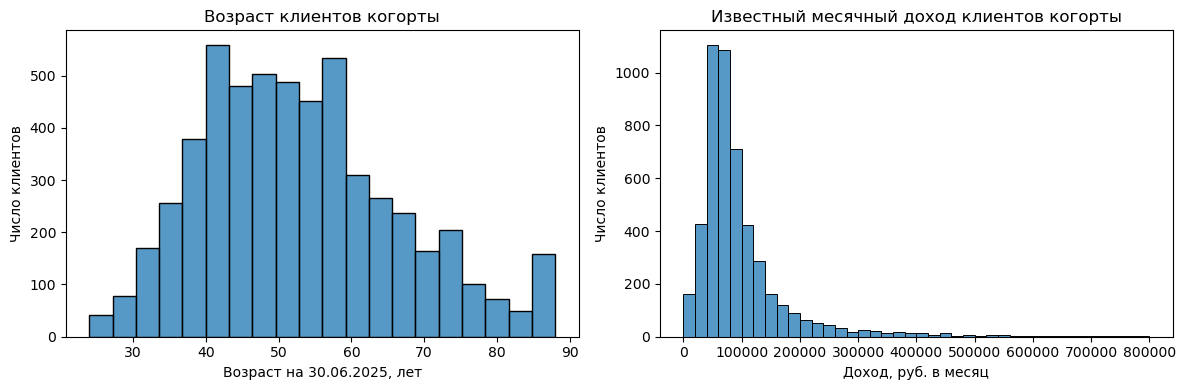

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(age_at_snapshot, bins=20, ax=axes[0])
axes[0].set_title("Возраст клиентов когорты")
axes[0].set_xlabel("Возраст на 30.06.2025, лет")
axes[0].set_ylabel("Число клиентов")

sns.histplot(cohort_income, bins=40, ax=axes[1])
axes[1].set_title("Известный месячный доход клиентов когорты")
axes[1].set_xlabel("Доход, руб. в месяц")
axes[1].set_ylabel("Число клиентов")

plt.tight_layout()
plt.show()

На момент 30 июня 2025 года в сопоставимой когорте было 5502 клиента. Медианный возрастсоставляет 51 год; первый и третий квартили - 43 и 61. Месячный доход был известен для 4953 клиентов: медиана составила 73800 рублей, среднее - 96899 рублей. Распределение дохода скошено вправо; 549 значений дохода отсутствовали. 

### 5.2. Частотные характеристики категориальных признаков

In [70]:
categorical_fields = [
    "segment",
    "loyalty_tier",
    "card_type",
    "has_mobile_app",
    "marketing_opt_in",
    "income_source",
    "satisfaction_score",
]

for field in categorical_fields:
    counts = clients_cohort[field].value_counts(dropna=False)

    frequency_table = pd.DataFrame({
        "число клиентов": counts,
        "доля от когорты, %": counts / len(clients_cohort) * 100,
    })

    print("\n---", field, "---")
    display(frequency_table.round(2))


--- segment ---


,число клиентов,"доля от когорты, %"
segment,,
Массовый,2824,51.33
Зарплатный,1576,28.64
Премиальный,857,15.58
Private,234,4.25
<NA>,11,0.20



--- loyalty_tier ---


,число клиентов,"доля от когорты, %"
loyalty_tier,,
Базовый,2771,50.36
Серебро,1478,26.86
Золото,947,17.21
Платина,306,5.56



--- card_type ---


,число клиентов,"доля от когорты, %"
card_type,,
Дебетовая,3810,69.25
Кредитная,1212,22.03
Премиальная,480,8.72


... (4 outputs left out)


--- income_source ---


,число клиентов,"доля от когорты, %"
income_source,,
Зарплата в нашем банке,2482,45.11
Зарплата в другом банке,1527,27.75
Не указан,1493,27.14



--- satisfaction_score ---


,число клиентов,"доля от когорты, %"
satisfaction_score,,
NaN,3291,59.81
5.0,579,10.52
3.0,463,8.42
2.0,444,8.07
4.0,433,7.87
1.0,292,5.31


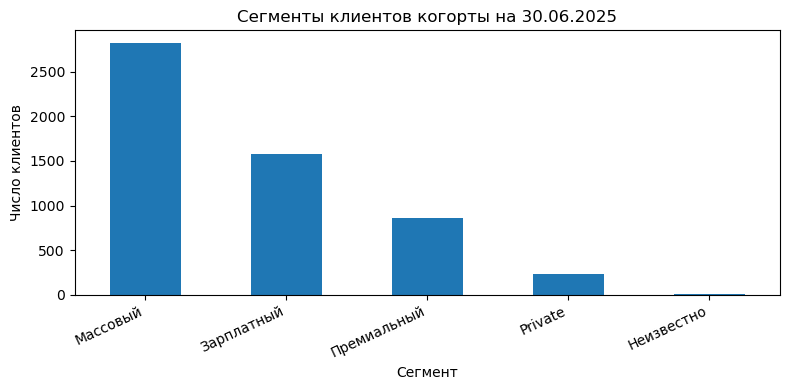

In [71]:
segment_for_plot = clients_cohort["segment"].fillna("Неизвестно")

segment_counts = segment_for_plot.value_counts()

ax = segment_counts.plot.bar(figsize=(8, 4))

ax.set_title("Сегменты клиентов когорты на 30.06.2025")
ax.set_xlabel("Сегмент")
ax.set_ylabel("Число клиентов")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Среди 5502 клиентов соспоставимой когорты на 30 июня 2025 года массовый сегмент составляет 2824 клиента, зарплатный - 1576 клиентов соответственно. Приложение указано у 3416 клиентов, согласие на маркетинг - у 4822 клиентов. Оценка удовлетворенности отсутсвует у 3291 клиента, поэтому выводы по ней ограничены наблюдаемыми ответами. 

### 5.3. Динамика по месяцам

In [72]:
txn_monthly = txn_for_activity.copy()

txn_monthly["month"] = (
    txn_monthly["txn_datetime"].dt.to_period("M")
)

all_months = pd.period_range(
    start="2024-01",
    end="2025-06",
    freq="M"
)

monthly_activity = (
    txn_monthly.groupby("month")
    .agg(
        operations=("txn_id", "size"),
        active_clients=("client_id", "nunique"),
    )
    .reindex(all_months, fill_value=0)
)

monthly_activity.index.name = "month"

cohort_size = len(clients_cohort)

monthly_activity["operations_per_client"] = (
    monthly_activity["operations"] / cohort_size
)

monthly_activity["active_clients_share_%"] = (
    monthly_activity["active_clients"] / cohort_size * 100
)

display(monthly_activity.round(2))

print("Клиентов в когорте:", cohort_size)
print("Сумма операций по месяцам:",
      monthly_activity["operations"].sum())
print("Строк в txn_for_activity:", len(txn_for_activity))

,operations,active_clients,operations_per_client,active_clients_share_%
month,,,,
2024-01,16046,4201,2.92,76.35
2024-02,20086,4380,3.65,79.61
2024-03,23082,4463,4.20,81.12
2024-04,22610,4425,4.11,80.43
2024-05,20608,4406,3.75,80.08
2024-06,22205,4428,4.04,80.48
2024-07,23315,4482,4.24,81.46
2024-08,23764,4519,4.32,82.13
2024-09,22696,4526,4.13,82.26


Клиентов в когорте: 5502
Сумма операций по месяцам: 385214
Строк в txn_for_activity: 385214


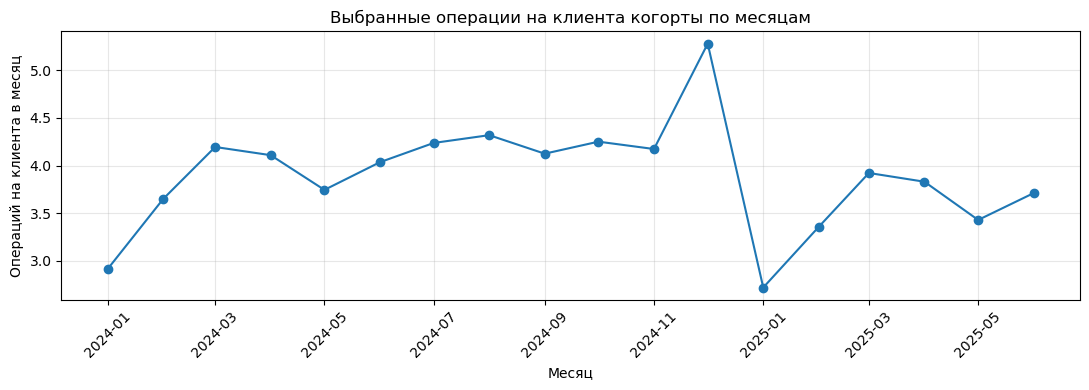

In [73]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    monthly_activity.index.to_timestamp(),
    monthly_activity["operations_per_client"],
    marker="o"
)

ax.set_title("Выбранные операции на клиента когорты по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Операций на клиента в месяц")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [74]:
periods = [
    ("2024 год", "2024-01", "2024-12"),
    ("Январь–июнь 2024", "2024-01", "2024-06"),
    ("Январь–июнь 2025", "2025-01", "2025-06"),
]

period_rows = []

for label, start, end in periods:
    period_data = monthly_activity.loc[start:end]

    months = len(period_data)
    operations = int(period_data["operations"].sum())

    period_rows.append({
        "период": label,
        "месяцев": months,
        "клиентов в когорте": cohort_size,
        "операций": operations,
        "операций на клиента в месяц": (
            operations / cohort_size / months
        ),
    })

period_summary = pd.DataFrame(period_rows).set_index("период")

display(period_summary.round(3))

,месяцев,клиентов в когорте,операций,операций на клиента в месяц
период,,,,
2024 год,12,5502,269807,4.086
Январь–июнь 2024,6,5502,124637,3.776
Январь–июнь 2025,6,5502,115407,3.496


In [75]:
base_year = period_summary.loc[
    "2024 год", "операций на клиента в месяц"
]

base_same_months = period_summary.loc[
    "Январь–июнь 2024", "операций на клиента в месяц"
]

current = period_summary.loc[
    "Январь–июнь 2025", "операций на клиента в месяц"
]

print(
    "Изменение относительно всего 2024 года, %:",
    round((current / base_year - 1) * 100, 2)
)

print(
    "Изменение относительно января–июня 2024 года, %:",
    round((current / base_same_months - 1) * 100, 2)
)

Изменение относительно всего 2024 года, %: -14.45
Изменение относительно января–июня 2024 года, %: -7.41


В сопоставимой когорте из 5502 клиентов среднее число успешных операций в каналах "Карта" и "Токен" снизилось с 4,086 операций на клиента в месяц за 2024 год до 3,496 за январь-июнь 2025 года. При сравнении одиноковых месяцев двух лет снижение составило 7,41%, что указывает на необходимость учитывать возможную сезонность. 

### 5.4. Разрезы и связи между признаками

In [76]:
client_segments = clients_cohort[["client_id", "segment"]].copy()

client_segments["segment_group"] = (
    client_segments["segment"].fillna("Неизвестно")
)

txn_with_segment = txn_for_activity.merge(
    client_segments[["client_id", "segment_group"]],
    on="client_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

if not txn_with_segment["_merge"].eq("both").all():
    raise ValueError("Не все операции связались с клиентом когорты.")

print("Строк операций до соединения:", len(txn_for_activity))
print("Строк операций после соединения:", len(txn_with_segment))

Строк операций до соединения: 385214
Строк операций после соединения: 385214


In [77]:
segment_sizes = client_segments["segment_group"].value_counts()

segment_base = txn_with_segment.loc[
    (txn_with_segment["txn_datetime"] >= "2024-01-01")
    & (txn_with_segment["txn_datetime"] < "2025-01-01")
].groupby("segment_group").size()

segment_current = txn_with_segment.loc[
    (txn_with_segment["txn_datetime"] >= "2025-01-01")
    & (txn_with_segment["txn_datetime"] < "2025-07-01")
].groupby("segment_group").size()

segment_comparison = pd.DataFrame({
    "клиентов": segment_sizes,
    "операций в 2024": segment_base.reindex(
        segment_sizes.index, fill_value=0
    ),
    "операций в январе–июне 2025": segment_current.reindex(
        segment_sizes.index, fill_value=0
    ),
})

segment_comparison["операций на клиента в месяц, 2024"] = (
    segment_comparison["операций в 2024"]
    / segment_comparison["клиентов"]
    / 12
)

segment_comparison["операций на клиента в месяц, 2025"] = (
    segment_comparison["операций в январе–июне 2025"]
    / segment_comparison["клиентов"]
    / 6
)

base_rate = segment_comparison["операций на клиента в месяц, 2024"]
current_rate = segment_comparison["операций на клиента в месяц, 2025"]

segment_comparison["изменение, %"] = (
    (current_rate / base_rate.where(base_rate != 0) - 1) * 100
)

display(segment_comparison.round(2))

,клиентов,операций в 2024,операций в январе–июне 2025,"операций на клиента в месяц, 2024","операций на клиента в месяц, 2025","изменение, %"
segment_group,,,,,,
Массовый,2824,122574,43679,3.62,2.58,-28.73
Зарплатный,1576,85963,42059,4.55,4.45,-2.15
Премиальный,857,47389,23144,4.61,4.50,-2.32
Private,234,13474,6334,4.80,4.51,-5.98
Неизвестно,11,407,191,3.08,2.89,-6.14


In [78]:
segment_contribution = pd.DataFrame({
    "клиентов": segment_comparison["клиентов"],
    "операций в месяц, 2024":
        segment_comparison["операций в 2024"] / 12,
    "операций в месяц, 2025":
        segment_comparison["операций в январе–июне 2025"] / 6,
})

segment_contribution["снижение операций в месяц"] = (
    segment_contribution["операций в месяц, 2024"]
    - segment_contribution["операций в месяц, 2025"]
)

total_decrease = segment_contribution["снижение операций в месяц"].sum()

if total_decrease != 0:
    segment_contribution["доля общего чистого снижения, %"] = (
        segment_contribution["снижение операций в месяц"]
        / total_decrease
        * 100
    )

display(segment_contribution.round(2))

print("Общее изменение числа операций в месяц:",
      round(total_decrease, 2))

,клиентов,"операций в месяц, 2024","операций в месяц, 2025",снижение операций в месяц,"доля общего чистого снижения, %"
segment_group,,,,,
Массовый,2824,10214.50,7279.83,2934.67,90.31
Зарплатный,1576,7163.58,7009.83,153.75,4.73
Премиальный,857,3949.08,3857.33,91.75,2.82
Private,234,1122.83,1055.67,67.17,2.07
Неизвестно,11,33.92,31.83,2.08,0.06


Общее изменение числа операций в месяц: 3249.42


In [79]:
segment_first_half_2024 = txn_with_segment.loc[
    (txn_with_segment["txn_datetime"] >= "2024-01-01")
    & (txn_with_segment["txn_datetime"] < "2024-07-01")
].groupby("segment_group").size()

same_months = pd.DataFrame({
    "клиентов": segment_sizes,
    "операций, январь–июнь 2024":
        segment_first_half_2024.reindex(
            segment_sizes.index, fill_value=0
        ),
    "операций, январь–июнь 2025":
        segment_current.reindex(
            segment_sizes.index, fill_value=0
        ),
})

same_months["на клиента в месяц, 2024"] = (
    same_months["операций, январь–июнь 2024"]
    / same_months["клиентов"]
    / 6
)

same_months["на клиента в месяц, 2025"] = (
    same_months["операций, январь–июнь 2025"]
    / same_months["клиентов"]
    / 6
)

same_base = same_months["на клиента в месяц, 2024"]
same_current = same_months["на клиента в месяц, 2025"]

same_months["изменение, %"] = (
    (same_current / same_base.where(same_base != 0) - 1) * 100
)

display(same_months.round(2))

,клиентов,"операций, январь–июнь 2024","операций, январь–июнь 2025","на клиента в месяц, 2024","на клиента в месяц, 2025","изменение, %"
segment_group,,,,,,
Массовый,2824,57278,43679,3.38,2.58,-23.74
Зарплатный,1576,39161,42059,4.14,4.45,7.40
Премиальный,857,21771,23144,4.23,4.50,6.31
Private,234,6250,6334,4.45,4.51,1.34
Неизвестно,11,177,191,2.68,2.89,7.91


In [80]:
mass_clients = clients_cohort.loc[
    clients_cohort["segment"].eq("Массовый").fillna(False),
    "client_id"
]

mass_size = len(mass_clients)

mass_all_channels = txn_success.loc[
    txn_success["client_id"].isin(mass_clients)
].copy()

print("Клиентов массового сегмента в когорте:", mass_size)
print("Успешных операций во всех каналах:", len(mass_all_channels))

Клиентов массового сегмента в когорте: 2824
Успешных операций во всех каналах: 245225


In [81]:
channel_periods = [
    ("2024", "2024-01-01", "2025-01-01", 12),
    ("2024_янв_июн", "2024-01-01", "2024-07-01", 6),
    ("2025_янв_июн", "2025-01-01", "2025-07-01", 6),
]

channel_tables = []

for label, start, end, months in channel_periods:
    period_ops = mass_all_channels.loc[
        (mass_all_channels["txn_datetime"] >= start)
        & (mass_all_channels["txn_datetime"] < end)
    ]

    channel_table = period_ops.groupby("channel", dropna=False).agg(
        операций=("txn_id", "size"),
        клиентов_с_операцией=("client_id", "nunique"),
    )

    channel_table = channel_table.add_prefix(label + "_")
    channel_tables.append(channel_table)

channel_comparison = (
    pd.concat(channel_tables, axis=1)
    .fillna(0)
    .astype(int)
)

channel_comparison["на клиента в месяц, 2024"] = (
    channel_comparison["2024_операций"] / mass_size / 12
)

channel_comparison["на клиента в месяц, янв–июн 2024"] = (
    channel_comparison["2024_янв_июн_операций"] / mass_size / 6
)

channel_comparison["на клиента в месяц, янв–июн 2025"] = (
    channel_comparison["2025_янв_июн_операций"] / mass_size / 6
)

channel_base = channel_comparison["на клиента в месяц, 2024"]
channel_same_months = (
    channel_comparison["на клиента в месяц, янв–июн 2024"]
)
channel_current = (
    channel_comparison["на клиента в месяц, янв–июн 2025"]
)

channel_comparison["изменение к 2024 году, %"] = (
    (channel_current / channel_base.where(channel_base != 0) - 1) * 100
)

channel_comparison["изменение к тем же месяцам, %"] = (
    (channel_current / channel_same_months.where(channel_same_months != 0) - 1)
    * 100
)

display(channel_comparison.round(2))

,2024_операций,2024_клиентов_с_операцией,2024_янв_июн_операций,2024_янв_июн_клиентов_с_операцией,2025_янв_июн_операций,2025_янв_июн_клиентов_с_операцией,"на клиента в месяц, 2024","на клиента в месяц, янв–июн 2024","на клиента в месяц, янв–июн 2025","изменение к 2024 году, %","изменение к тем же месяцам, %"
channel,,,,,,,,,,,
Карта,96677,2639,45143,2506,28404,2637,2.85,2.66,1.68,-41.24,-37.08
Онлайн-банк,27676,2508,12966,2267,7675,2083,0.82,0.77,0.45,-44.54,-40.81
СБП,32439,2536,14989,2305,11182,2233,0.96,0.88,0.66,-31.06,-25.40
Токен,25897,2409,12135,2073,15275,2001,0.76,0.72,0.90,17.97,25.88


In [82]:
mass_card_ops = txn_for_activity.loc[
    txn_for_activity["client_id"].isin(mass_clients)
].copy()

category_periods = [
    ("2024", "2024-01-01", "2025-01-01"),
    ("2024_янв_июн", "2024-01-01", "2024-07-01"),
    ("2025_янв_июн", "2025-01-01", "2025-07-01"),
]

category_tables = []

for label, start, end in category_periods:
    period_ops = mass_card_ops.loc[
        (mass_card_ops["txn_datetime"] >= start)
        & (mass_card_ops["txn_datetime"] < end)
    ]

    category_table = period_ops.groupby(
        "category", dropna=False
    ).agg(
        операций=("txn_id", "size"),
        клиентов_с_операцией=("client_id", "nunique"),
    )

    category_tables.append(category_table.add_prefix(label + "_"))

category_comparison = (
    pd.concat(category_tables, axis=1)
    .fillna(0)
    .astype(int)
)

category_comparison["операций в месяц, 2024"] = (
    category_comparison["2024_операций"] / 12
)

category_comparison["операций в месяц, 2025"] = (
    category_comparison["2025_янв_июн_операций"] / 6
)

category_comparison["снижение операций в месяц"] = (
    category_comparison["операций в месяц, 2024"]
    - category_comparison["операций в месяц, 2025"]
)

category_same_base = category_comparison["2024_янв_июн_операций"]
category_same_current = category_comparison["2025_янв_июн_операций"]

category_comparison["изменение к тем же месяцам, %"] = (
    (
        category_same_current
        / category_same_base.where(category_same_base != 0)
        - 1
    )
    * 100
)

category_comparison = category_comparison.sort_values(
    "снижение операций в месяц",
    ascending=False
)

display(category_comparison.round(2))

,2024_операций,2024_клиентов_с_операцией,2024_янв_июн_операций,2024_янв_июн_клиентов_с_операцией,2025_янв_июн_операций,2025_янв_июн_клиентов_с_операцией,"операций в месяц, 2024","операций в месяц, 2025",снижение операций в месяц,"изменение к тем же месяцам, %"
category,,,,,,,,,,
Продукты,36483,2596,17035,2436,13175,2466,3040.25,2195.83,844.42,-22.66
Транспорт,15964,2471,7477,2172,4931,1868,1330.33,821.83,508.50,-34.05
Кафе и рестораны,12199,2387,5733,2040,4391,1789,1016.58,731.83,284.75,-23.41
Связь и интернет,10987,2364,5156,1974,3949,1729,915.58,658.17,257.42,-23.41
Аптеки,10862,2380,5123,1975,3896,1717,905.17,649.33,255.83,-23.95
Одежда и обувь,10803,2350,5093,1940,3957,1749,900.25,659.50,240.75,-22.31
АЗС,9623,2326,4487,1895,3587,1693,801.92,597.83,204.08,-20.06
Онлайн-сервисы,8513,2267,3906,1786,3166,1553,709.42,527.67,181.75,-18.95
Развлечения и досуг,7140,2156,3268,1628,2627,1408,595.00,437.83,157.17,-19.61


In [83]:
print(
    "Операций по категориям за 2024 год:",
    category_comparison["2024_операций"].sum()
)

print(
    "Операций по категориям за январь–июнь 2025 года:",
    category_comparison["2025_янв_июн_операций"].sum()
)

Операций по категориям за 2024 год: 122574
Операций по категориям за январь–июнь 2025 года: 43679


In [84]:
expected_category = mass_card_ops["mcc_code"].map(dominant_category)

comparable = (
    mass_card_ops["category"].notna()
    & expected_category.notna()
)

category_mcc_disagree = (
    comparable
    & mass_card_ops["category"].ne(expected_category).fillna(False)
)

print("Всего выбранных операций массового сегмента:", len(mass_card_ops))
print("Расхождений категории с ориентиром по MCC:",
      category_mcc_disagree.sum())
print("Строк, которые не удалось сравнить:", (~comparable).sum())

mass_without_mcc_disagreement = mass_card_ops.loc[
    ~category_mcc_disagree
]

Всего выбранных операций массового сегмента: 166253
Расхождений категории с ориентиром по MCC: 471
Строк, которые не удалось сравнить: 0


In [85]:
base_without = mass_without_mcc_disagreement.loc[
    (mass_without_mcc_disagreement["txn_datetime"] >= "2024-01-01")
    & (mass_without_mcc_disagreement["txn_datetime"] < "2025-01-01")
].groupby("category").size()

current_without = mass_without_mcc_disagreement.loc[
    (mass_without_mcc_disagreement["txn_datetime"] >= "2025-01-01")
    & (mass_without_mcc_disagreement["txn_datetime"] < "2025-07-01")
].groupby("category").size()

category_sensitivity = pd.DataFrame({
    "снижение в месяц, все строки":
        category_comparison["снижение операций в месяц"],

    "операций в 2024 без расхождений":
        base_without.reindex(category_comparison.index, fill_value=0),

    "операций в 2025 без расхождений":
        current_without.reindex(category_comparison.index, fill_value=0),
})

category_sensitivity["снижение в месяц, без расхождений"] = (
    category_sensitivity["операций в 2024 без расхождений"] / 12
    - category_sensitivity["операций в 2025 без расхождений"] / 6
)

display(
    category_sensitivity.sort_values(
        "снижение в месяц, все строки",
        ascending=False
    ).round(2)
)

,"снижение в месяц, все строки",операций в 2024 без расхождений,операций в 2025 без расхождений,"снижение в месяц, без расхождений"
category,,,,
Продукты,844.42,36384,13138,842.33
Транспорт,508.50,15914,4911,507.67
Кафе и рестораны,284.75,12163,4379,283.75
Связь и интернет,257.42,10957,3938,256.75
Аптеки,255.83,10827,3884,254.92
Одежда и обувь,240.75,10774,3944,240.50
АЗС,204.08,9594,3580,202.83
Онлайн-сервисы,181.75,8496,3159,181.50
Развлечения и досуг,157.17,7121,2619,156.92


## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

Активность клиента - среднее число успешных операций в каналак "Карта" и "Токен" на месяц. Суммы операций не используются: операции в разных валютах учитывается по их кооличеству. Для каждого клиента из когорты (5502 клиента, которые присутствуют в справочнике дейтвующих клиентов на 30 июня 2025 года и зарегистрированы не позднее 1 января 2024 года): 

базовая активность = число выбранных операций за 2024 год / 12;
текущая активность = число выбранных операций за январь-июнь 2025 года / 6;
относительное снижение = (базовая активность - текущая активность) / базовая активность * 100%. 

Клиенты без подходящих операций в каком-либо периоде сохраняется с нулевым числом операций. 
Если в 2024 году у клиента не было таких операций, относительное изменение не определено (делить на ноль нельзя).  

In [86]:
base_ops = txn_for_activity.loc[
    (txn_for_activity["txn_datetime"] >= "2024-01-01")
    & (txn_for_activity["txn_datetime"] < "2025-01-01")
]

current_ops = txn_for_activity.loc[
    (txn_for_activity["txn_datetime"] >= "2025-01-01")
    & (txn_for_activity["txn_datetime"] < "2025-07-01")
]

base_count_by_client = base_ops.groupby("client_id").size()
current_count_by_client = current_ops.groupby("client_id").size()

client_activity = clients_cohort.copy()

client_activity["operations_2024"] = (
    client_activity["client_id"]
    .map(base_count_by_client)
    .fillna(0)
    .astype(int)
)

client_activity["operations_2025_h1"] = (
    client_activity["client_id"]
    .map(current_count_by_client)
    .fillna(0)
    .astype(int)
)

client_activity["base_per_month"] = (
    client_activity["operations_2024"] / 12
)

client_activity["current_per_month"] = (
    client_activity["operations_2025_h1"] / 6
)

client_activity["fall_percent"] = (
    1
    - client_activity["current_per_month"]
    / client_activity["base_per_month"].where(
        client_activity["base_per_month"] > 0
    )
) * 100

print("Клиентов в итоговой таблице:", len(client_activity))
print("Повторных client_id:", client_activity["client_id"].duplicated().sum())

print("\nСумма операций клиентов за 2024:",
      client_activity["operations_2024"].sum())

print("Сумма операций клиентов за январь–июнь 2025:",
      client_activity["operations_2025_h1"].sum())

Клиентов в итоговой таблице: 5502
Повторных client_id: 0

Сумма операций клиентов за 2024: 269807
Сумма операций клиентов за январь–июнь 2025: 115407


In [87]:
base_count = client_activity["operations_2024"]
current_count = client_activity["operations_2025_h1"]

client_activity["activity_change"] = np.select(
    [
        (base_count == 0) & (current_count == 0),
        (base_count == 0) & (current_count > 0),
        (base_count > 0) & (2 * current_count < base_count),
        (base_count > 0) & (2 * current_count == base_count),
        (base_count > 0) & (2 * current_count > base_count),
    ],
    [
        "Нет операций в обоих периодах",
        "Нет базы, появились операции",
        "Активность снизилась",
        "Активность не изменилась",
        "Активность выросла",
    ],
    default="Требует проверки",
)

change_counts = client_activity["activity_change"].value_counts()

change_summary = pd.DataFrame({
    "клиентов": change_counts,
    "доля от когорты, %": change_counts / len(client_activity) * 100,
})

display(change_summary.round(2))

,клиентов,"доля от когорты, %"
activity_change,,
Активность снизилась,3318,60.31
Активность выросла,1684,30.61
"Нет базы, появились операции",355,6.45
Активность не изменилась,114,2.07
Нет операций в обоих периодах,31,0.56


Данная метрика не видит: снижение суммы трат, если число операций не изменилось; использование СБП и Онлайн-банка; отмену успешной покупки последующим возвратом; изменения внутри категории или канала, если общее число выбранных операций осталось прежним. 

В сопоставимой когорте из 5502 клиентов среднее число успешных операций в каналах "Карта" и "Токен" снизилось у 3318 человек. Обнаружено 5116 клиентов с ненулевой активностью. Для 386 клиентов базовая активность была нулевой, для них относительное изменение не рассчитывалось. 

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

Общие условия отбора. В предварительную компанию рассматриваются клиенты сопоставимой когорты, у которых: 
1) есть согласие на маркетинговую коммуникацию;
2) была ненулевая активность в базовом периоде;
3) среднее число операций в месяц снизилось;
4) есть единственная категория, давшая наибольшее снижение числа операций в месяц. 

Для каждой категории вклад в изменение рассчитывается как: 
операции за 2024 год / 12 - операции за январь-июнь / 6

Ведущая категория - категория с наибольшим положительным вкладом в снижение. Есл максимальный вклад одинаков у нескольких категорий, то клиент в этом варианте кампании не включается (вобрать одну ведущую категорию без доп. основания нельзя). 

In [88]:
group_candidates = client_activity.copy()

group_candidates["segment_group"] = (
    group_candidates["segment"].fillna("Неизвестно")
)

group_candidates["has_baseline"] = (
    group_candidates["operations_2024"] > 0
)

group_candidates["declined"] = (
    group_candidates["activity_change"] == "Активность снизилась"
)

group_candidates["declined_and_consent"] = (
    group_candidates["declined"]
    & group_candidates["marketing_opt_in"].eq("Да")
)

candidate_by_segment = group_candidates.groupby(
    "segment_group", dropna=False
).agg(
    клиентов=("client_id", "size"),
    с_ненулевой_базой=("has_baseline", "sum"),
    со_снижением=("declined", "sum"),
    снижение_и_согласие=("declined_and_consent", "sum"),
)

candidate_by_segment["снижение_среди_имеющих_базу, %"] = (
    candidate_by_segment["со_снижением"]
    / candidate_by_segment["с_ненулевой_базой"].replace(0, np.nan)
    * 100
)

display(candidate_by_segment.round(2))

,клиентов,с_ненулевой_базой,со_снижением,снижение_и_согласие,"снижение_среди_имеющих_базу, %"
segment_group,,,,,
Private,234,213,126,112,59.15
Зарплатный,1576,1457,769,684,52.78
Массовый,2824,2663,1982,1727,74.43
Неизвестно,11,10,6,6,60.00
Премиальный,857,773,435,383,56.27


In [89]:
declined_with_consent = group_candidates.loc[
    group_candidates["declined_and_consent"]
].copy()

print("Клиентов со снижением и согласием:",
      len(declined_with_consent))

print("\nРаспределение относительного снижения, %:")
display(
    declined_with_consent["fall_percent"]
    .quantile([0.25, 0.50, 0.75, 1.00])
    .round(2)
)

print(
    "\nИз них без выбранных операций в январе–июне 2025:",
    (declined_with_consent["operations_2025_h1"] == 0).sum()
)

print(
    "Из них менее 12 выбранных операций за 2024 год:",
    (declined_with_consent["operations_2024"] < 12).sum()
)

Клиентов со снижением и согласием: 2912

Распределение относительного снижения, %:


0.25     18.83
0.50     38.46
0.75     63.18
1.00    100.00
Name: fall_percent, dtype: float64


Из них без выбранных операций в январе–июне 2025: 82
Из них менее 12 выбранных операций за 2024 год: 200


In [90]:
candidate_factors = declined_with_consent.copy()

factors = [
    ("channel", "Карта", "card"),
    ("channel", "Токен", "token"),
    ("category", "Продукты", "food"),
    ("category", "Транспорт", "transport"),
]

for field, value, name in factors:
    base_counts = (
        base_ops.loc[base_ops[field].eq(value)]
        .groupby("client_id")
        .size()
    )

    current_counts = (
        current_ops.loc[current_ops[field].eq(value)]
        .groupby("client_id")
        .size()
    )

    candidate_factors[name + "_2024"] = (
        candidate_factors["client_id"]
        .map(base_counts)
        .fillna(0)
        .astype(int)
    )

    candidate_factors[name + "_2025_h1"] = (
        candidate_factors["client_id"]
        .map(current_counts)
        .fillna(0)
        .astype(int)
    )

    candidate_factors[name + "_decline"] = (
        (candidate_factors[name + "_2024"] > 0)
        & (
            2 * candidate_factors[name + "_2025_h1"]
            < candidate_factors[name + "_2024"]
        )
    )

In [91]:
candidate_factors["segment_group"] = (
    candidate_factors["segment"].fillna("Неизвестно")
)

factor_summary = candidate_factors.groupby(
    "segment_group", dropna=False
).agg(
    кандидатов=("client_id", "size"),
    снизилась_Карта=("card_decline", "sum"),
    снизился_Токен=("token_decline", "sum"),
    снизились_Продукты=("food_decline", "sum"),
    снизился_Транспорт=("transport_decline", "sum"),
)

display(factor_summary)

,кандидатов,снизилась_Карта,снизился_Токен,снизились_Продукты,снизился_Транспорт
segment_group,,,,,
Private,112,102,72,60,86
Зарплатный,684,630,410,488,462
Массовый,1727,1647,1211,1419,1293
Неизвестно,6,6,4,5,4
Премиальный,383,353,238,240,276


In [92]:
overlap_card_food = pd.crosstab(
    candidate_factors["card_decline"],
    candidate_factors["food_decline"],
    margins=True
)

display(overlap_card_food)

food_decline,False,True,All
card_decline,,,
False,76,98,174
True,624,2114,2738
All,700,2212,2912


In [93]:
same_month_base_ops = txn_for_activity.loc[
    (txn_for_activity["txn_datetime"] >= "2024-01-01")
    & (txn_for_activity["txn_datetime"] < "2024-07-01")
]

same_month_base_counts = (
    same_month_base_ops.groupby("client_id").size()
)

candidate_factors["operations_2024_h1"] = (
    candidate_factors["client_id"]
    .map(same_month_base_counts)
    .fillna(0)
    .astype(int)
)

first_half_2024 = candidate_factors["operations_2024_h1"]
first_half_2025 = candidate_factors["operations_2025_h1"]

candidate_factors["same_months_change"] = np.select(
    [
        (first_half_2024 == 0) & (first_half_2025 == 0),
        (first_half_2024 == 0) & (first_half_2025 > 0),
        (first_half_2024 > 0) & (first_half_2025 < first_half_2024),
        (first_half_2024 > 0) & (first_half_2025 == first_half_2024),
        (first_half_2024 > 0) & (first_half_2025 > first_half_2024),
    ],
    [
        "Нет операций в обоих полугодиях",
        "Нет базы, появились операции",
        "Снижение",
        "Без изменения",
        "Рост",
    ],
    default="Требует проверки",
)

same_months_counts = (
    candidate_factors["same_months_change"].value_counts()
)

same_months_summary = pd.DataFrame({
    "клиентов": same_months_counts,
    "доля от 2912 кандидатов, %":
        same_months_counts / len(candidate_factors) * 100,
})

display(same_months_summary.round(2))

,клиентов,"доля от 2912 кандидатов, %"
same_months_change,,
Снижение,2434,83.59
Рост,340,11.68
Без изменения,114,3.91
"Нет базы, появились операции",13,0.45
Нет операций в обоих полугодиях,11,0.38


In [94]:
candidate_profile = candidate_factors.copy()

candidate_profile["app_group"] = (
    candidate_profile["has_mobile_app"].fillna("Неизвестно")
)

candidate_profile["no_current_operations"] = (
    candidate_profile["operations_2025_h1"] == 0
)

candidate_profile["fall_at_least_50"] = (
    candidate_profile["fall_percent"] >= 50
)

candidate_profile["low_baseline"] = (
    candidate_profile["operations_2024"] < 12
)

profile_table = candidate_profile.groupby(
    ["segment_group", "app_group"], dropna=False
).agg(
    кандидатов=("client_id", "size"),
    снизилась_Карта=("card_decline", "sum"),
    снизились_Продукты=("food_decline", "sum"),
    снизился_Транспорт=("transport_decline", "sum"),
    нет_операций_в_2025=("no_current_operations", "sum"),
    снижение_не_меньше_50_процентов=("fall_at_least_50", "sum"),
    меньше_12_операций_в_2024=("low_baseline", "sum"),
)

display(profile_table)

кандидатов  снизилась_Карта  снизились_Продукты  снизился_Транспорт  нет_операций_в_2025  снижение_не_меньше_50_процентов  \
segment_group app_group                                                                                                                              
Private       Да                 64               56                  37                  45                    2                                8   
              Нет                48               46                  23                  41                    1                               14   
Зарплатный    Да                427              390                 298                 278                   10                               77   
              Нет               257              240                 190                 184                    2                               82   
Массовый      Да               1006              944                 798                 722                   32                              438   
              Нет               721              703                 621                 571                   30                              468   
Неизвестно    Да                  4                4                   3                   3                    0                                1   
              Нет                 2                2                   2                   1                    0                                1   
Премиальный   Да                246              221                 155                 174                    2                               44   
              Нет               137              132                  85                 102                    3                               46   

                         меньше_12_операций_в_2024  
segment_group app_group                             
Private       Да                                 6  
              Нет                                2  
Зарплатный    Да                                21  
              Нет                               22  
Массовый      Да                                68  
              Нет                               52  
Неизвестно    Да                                 0  
              Нет                                1  
Премиальный   Да                                19  
              Нет                                9

In [95]:
if txn_for_activity["category"].isna().any():
    raise ValueError(
        "Есть операции без категории. Сначала нужно решить, как их учитывать."
    )

categories = sorted(txn_for_activity["category"].unique())

candidate_ids = candidate_factors["client_id"]

category_base = (
    base_ops.groupby(["client_id", "category"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=candidate_ids, columns=categories, fill_value=0)
)

category_current = (
    current_ops.groupby(["client_id", "category"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=candidate_ids, columns=categories, fill_value=0)
)

category_loss_units = category_base - 2 * category_current

category_loss = category_loss_units / 12

In [96]:
candidate_by_id = (
    candidate_factors.set_index("client_id")
    .reindex(category_loss_units.index)
)

expected_loss_units = (
    candidate_by_id["operations_2024"]
    - 2 * candidate_by_id["operations_2025_h1"]
)

if not np.array_equal(
    category_loss_units.sum(axis=1).to_numpy(),
    expected_loss_units.to_numpy()
):
    raise ValueError(
        "Сумма изменений по категориям не совпадает с общим изменением."
    )

max_loss_units = category_loss_units.max(axis=1)

if not max_loss_units.gt(0).all():
    raise ValueError(
        "Для некоторых кандидатов не найдено снижение по категориям."
    )

leading_category = category_loss_units.idxmax(axis=1)

number_of_maxima = category_loss_units.eq(
    max_loss_units, axis=0
).sum(axis=1)

candidate_factors["leading_category"] = (
    candidate_factors["client_id"].map(leading_category)
)

candidate_factors["leading_category_tie"] = (
    candidate_factors["client_id"].map(number_of_maxima.gt(1))
)

print("Кандидатов:", len(candidate_factors))
print(
    "Из них с одинаковым максимальным вкладом нескольких категорий:",
    candidate_factors["leading_category_tie"].sum()
)

Кандидатов: 2912
Из них с одинаковым максимальным вкладом нескольких категорий: 418


In [97]:
leading_by_segment = pd.crosstab(
    candidate_factors["segment_group"],
    candidate_factors["leading_category"],
    margins=True
)

display(leading_by_segment)

leading_category,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт,All
segment_group,,,,,,,,,,
Private,9,3,29,6,7,13,14,1,30,112
Зарплатный,76,34,96,51,28,232,23,29,115,684
Массовый,99,94,144,98,54,892,34,73,239,1727
Неизвестно,2,1,0,0,1,1,0,0,1,6
Премиальный,31,10,61,45,8,77,23,4,124,383
All,217,142,330,200,98,1215,94,107,509,2912


In [98]:
leading_by_segment_app = pd.crosstab(
    [
        candidate_factors["segment_group"],
        candidate_factors["has_mobile_app"],
    ],
    candidate_factors["leading_category"],
    margins=True
)

display(leading_by_segment_app)

leading_category              АЗС  Аптеки  Кафе и рестораны  Одежда и обувь  Онлайн-сервисы  Продукты  Развлечения и досуг  Связь и интернет  Транспорт   All
segment_group has_mobile_app                                                                                                                                 
Private       Да                7       2                18               4               5         9                    6                 1         12    64
              Нет               2       1                11               2               2         4                    8                 0         18    48
Зарплатный    Да               46      19                53              31              16       148                   18                18         78   427
              Нет              30      15                43              20              12        84                    5                11         37   257
Массовый      Да               60      60                85              57              43       490                   24                41        146  1006
              Нет              39      34                59              41              11       402                   10                32         93   721
Неизвестно    Да                1       0                 0               0               1         1                    0                 0          1     4
              Нет               1       1                 0               0               0         0                    0                 0          0     2
Премиальный   Да               22       6                38              28               4        49                   14                 3         82   246
              Нет               9       4                23              17               4        28                    9                 1         42   137
All                           217     142               330             200              98      1215                   94               107        509  2912

In [99]:
# Предварительные правила
rules = {
    "Массовый, приложение, продукты": (
        candidate_factors["segment_group"].eq("Массовый")
        & candidate_factors["has_mobile_app"].eq("Да")
        & candidate_factors["leading_category"].eq("Продукты")
    ),

    "Массовый, без приложения, продукты": (
        candidate_factors["segment_group"].eq("Массовый")
        & candidate_factors["has_mobile_app"].eq("Нет")
        & candidate_factors["leading_category"].eq("Продукты")
    ),

    "Массовый, транспорт": (
        candidate_factors["segment_group"].eq("Массовый")
        & candidate_factors["leading_category"].eq("Транспорт")
    ),

    "Зарплатный, продукты": (
        candidate_factors["segment_group"].eq("Зарплатный")
        & candidate_factors["leading_category"].eq("Продукты")
    ),
}

rule_matches = pd.DataFrame(rules).fillna(False)

print("Клиентов, подходящих более чем под одно правило:",
      (rule_matches.sum(axis=1) > 1).sum())

print("Клиентов, подходящих хотя бы под одно правило:",
      (rule_matches.sum(axis=1) > 0).sum())

print("Кандидатов, не попавших ни под одно правило:",
      (rule_matches.sum(axis=1) == 0).sum())

Клиентов, подходящих более чем под одно правило: 0
Клиентов, подходящих хотя бы под одно правило: 1363
Кандидатов, не попавших ни под одно правило: 1549


In [100]:
group_review_rows = []

for group_name in rule_matches.columns:
    group = candidate_factors.loc[rule_matches[group_name]]
    n = len(group)

    if n == 0:
        continue

    base_rate = group["operations_2024"].sum() / n / 12
    current_rate = group["operations_2025_h1"].sum() / n / 6

    group_review_rows.append({
        "группа": group_name,
        "клиентов": n,
        "на клиента в месяц, 2024": base_rate,
        "на клиента в месяц, 2025": current_rate,
        "изменение средней активности, %":
            (current_rate / base_rate - 1) * 100,
        "медианное снижение клиента, %":
            group["fall_percent"].median(),
        "равные ведущие категории":
            group["leading_category_tie"].sum(),
        "меньше 12 операций за 2024":
            (group["operations_2024"] < 12).sum(),
        "нет выбранных операций в 2025":
            (group["operations_2025_h1"] == 0).sum(),
    })

group_review = pd.DataFrame(group_review_rows).set_index("группа")
display(group_review.round(2))

,клиентов,"на клиента в месяц, 2024","на клиента в месяц, 2025","изменение средней активности, %","медианное снижение клиента, %",равные ведущие категории,меньше 12 операций за 2024,нет выбранных операций в 2025
группа,,,,,,,,
"Массовый, приложение, продукты",490,4.34,2.20,-49.22,56.95,25,28,21
"Массовый, без приложения, продукты",402,4.10,1.62,-60.43,64.96,32,20,18
"Массовый, транспорт",239,4.39,2.90,-33.85,33.33,0,17,6
"Зарплатный, продукты",232,5.48,3.54,-35.35,36.18,10,18,2


In [101]:
print(
    "Всего кандидатов с равными максимальными вкладами:",
    candidate_factors["leading_category_tie"].sum()
)

leading_reverse = category_loss_units[
    category_loss_units.columns[::-1]
].idxmax(axis=1)

reverse_candidates = candidate_factors.copy()

reverse_candidates["leading_category"] = (
    reverse_candidates["client_id"].map(leading_reverse)
)

reverse_rules = pd.DataFrame({
    "Массовый, приложение, продукты": (
        reverse_candidates["segment_group"].eq("Массовый")
        & reverse_candidates["has_mobile_app"].eq("Да")
        & reverse_candidates["leading_category"].eq("Продукты")
    ),

    "Массовый, без приложения, продукты": (
        reverse_candidates["segment_group"].eq("Массовый")
        & reverse_candidates["has_mobile_app"].eq("Нет")
        & reverse_candidates["leading_category"].eq("Продукты")
    ),

    "Массовый, транспорт": (
        reverse_candidates["segment_group"].eq("Массовый")
        & reverse_candidates["leading_category"].eq("Транспорт")
    ),

    "Зарплатный, продукты": (
        reverse_candidates["segment_group"].eq("Зарплатный")
        & reverse_candidates["leading_category"].eq("Продукты")
    ),
}).fillna(False)

tie_sensitivity_rows = []

for group_name in rule_matches.columns:
    original = rule_matches[group_name]
    alternative = reverse_rules[group_name]

    tie_sensitivity_rows.append({
        "группа": group_name,
        "первая по алфавиту": int(original.sum()),
        "последняя по алфавиту": int(alternative.sum()),
        "вышли из группы": int((original & ~alternative).sum()),
        "вошли в группу": int((~original & alternative).sum()),
    })

tie_sensitivity = pd.DataFrame(
    tie_sensitivity_rows
).set_index("группа")

display(tie_sensitivity)

print(
    "Всего в группах при альтернативном правиле:",
    reverse_rules.any(axis=1).sum()
)

print(
    "Пересечений при альтернативном правиле:",
    (reverse_rules.sum(axis=1) > 1).sum()
)

Всего кандидатов с равными максимальными вкладами: 418


,первая по алфавиту,последняя по алфавиту,вышли из группы,вошли в группу
группа,,,,
"Массовый, приложение, продукты",490,499,25,34
"Массовый, без приложения, продукты",402,398,32,28
"Массовый, транспорт",239,334,0,95
"Зарплатный, продукты",232,245,10,23


Всего в группах при альтернативном правиле: 1476
Пересечений при альтернативном правиле: 0


In [102]:
unique_leading = (
    candidate_factors["leading_category_tie"]
    .fillna(False)
    .eq(False)
)

strict_rules = rule_matches.copy()
strict_rules.loc[~unique_leading, :] = False

strict_review_rows = []

for group_name in strict_rules.columns:
    original_mask = rule_matches[group_name]
    strict_mask = strict_rules[group_name]

    group = candidate_factors.loc[strict_mask]

    strict_review_rows.append({
        "группа": group_name,
        "было по первому правилу": int(original_mask.sum()),
        "с единственной ведущей категорией": len(group),
        "исключено из группы из-за равенства":
            int((original_mask & ~unique_leading).sum()),
        "снижение при сравнении одинаковых полугодий":
            int(group["same_months_change"].eq("Снижение").sum()),
        "меньше 12 операций за 2024":
            int((group["operations_2024"] < 12).sum()),
    })

strict_review = pd.DataFrame(
    strict_review_rows
).set_index("группа")

display(strict_review)

print(
    "Всего в четырёх группах:",
    strict_rules.any(axis=1).sum()
)

print(
    "Клиентов более чем в одной группе:",
    (strict_rules.sum(axis=1) > 1).sum()
)

,было по первому правилу,с единственной ведущей категорией,исключено из группы из-за равенства,снижение при сравнении одинаковых полугодий,меньше 12 операций за 2024
группа,,,,,
"Массовый, приложение, продукты",490,465,25,415,23
"Массовый, без приложения, продукты",402,370,32,357,13
"Массовый, транспорт",239,239,0,199,17
"Зарплатный, продукты",232,222,10,181,16


Всего в четырёх группах: 1296
Клиентов более чем в одной группе: 0


In [103]:
expected_for_mcc = txn_for_activity["mcc_code"].map(dominant_category)

mcc_comparable = (
    txn_for_activity["category"].notna()
    & expected_for_mcc.notna()
)

mcc_disagreement = (
    mcc_comparable
    & txn_for_activity["category"]
        .ne(expected_for_mcc)
        .fillna(False)
)

print("Всего выбранных операций:", len(txn_for_activity))
print("Операций с расхождением:", mcc_disagreement.sum())
print("Операций, которые нельзя сравнить:", (~mcc_comparable).sum())

mcc_period_rows = []

for label, start, end in [
    ("2024 год", "2024-01-01", "2025-01-01"),
    ("Январь–июнь 2025", "2025-01-01", "2025-07-01"),
]:
    in_window = (
        (txn_for_activity["txn_datetime"] >= start)
        & (txn_for_activity["txn_datetime"] < end)
    )

    disagree_in_window = in_window & mcc_disagreement
    n_operations = int(in_window.sum())
    n_disagreements = int(disagree_in_window.sum())

    mcc_period_rows.append({
        "период": label,
        "операций": n_operations,
        "расхождений": n_disagreements,
        "доля расхождений, %":
            n_disagreements / n_operations * 100,
        "клиентов с расхождениями":
            txn_for_activity.loc[
                disagree_in_window, "client_id"
            ].nunique(),
    })

mcc_period_summary = pd.DataFrame(
    mcc_period_rows
).set_index("период")

display(mcc_period_summary.round(2))

Всего выбранных операций: 385214
Операций с расхождением: 1066
Операций, которые нельзя сравнить: 0


,операций,расхождений,"доля расхождений, %",клиентов с расхождениями
период,,,,
2024 год,269807,761,0.28,686
Январь–июнь 2025,115407,305,0.26,287


In [104]:
# Временный вариант для проверки.
alt_transactions = txn_for_activity.loc[
    ~mcc_disagreement
].copy()

alt_base_ops = alt_transactions.loc[
    (alt_transactions["txn_datetime"] >= "2024-01-01")
    & (alt_transactions["txn_datetime"] < "2025-01-01")
]

alt_current_ops = alt_transactions.loc[
    (alt_transactions["txn_datetime"] >= "2025-01-01")
    & (alt_transactions["txn_datetime"] < "2025-07-01")
]

print("Операций после временного исключения:", len(alt_transactions))
print("Из них за 2024 год:", len(alt_base_ops))
print("Из них за январь–июнь 2025:", len(alt_current_ops))

alt_base_counts = alt_base_ops.groupby("client_id").size()
alt_current_counts = alt_current_ops.groupby("client_id").size()

alt_clients = clients_cohort.copy()

alt_clients["base_count"] = (
    alt_clients["client_id"]
    .map(alt_base_counts)
    .fillna(0)
    .astype(int)
)

alt_clients["current_count"] = (
    alt_clients["client_id"]
    .map(alt_current_counts)
    .fillna(0)
    .astype(int)
)

alt_eligible = (
    (alt_clients["base_count"] > 0)
    & (2 * alt_clients["current_count"] < alt_clients["base_count"])
    & alt_clients["marketing_opt_in"].eq("Да").fillna(False)
)

alt_candidates = alt_clients.loc[alt_eligible].copy()

print("\nКандидатов в основном варианте:", len(candidate_factors))
print("Кандидатов в варианте без расхождений:", len(alt_candidates))

Операций после временного исключения: 384148
Из них за 2024 год: 269046
Из них за январь–июнь 2025: 115102

Кандидатов в основном варианте: 2912
Кандидатов в варианте без расхождений: 2910


In [105]:
if alt_candidates.empty:
    raise ValueError("В альтернативном варианте нет кандидатов.")

alt_ids = pd.Index(alt_candidates["client_id"], name="client_id")

category_columns = list(category_loss_units.columns)

alt_category_base = (
    alt_base_ops.groupby(["client_id", "category"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=alt_ids, columns=category_columns, fill_value=0)
)

alt_category_current = (
    alt_current_ops.groupby(["client_id", "category"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=alt_ids, columns=category_columns, fill_value=0)
)

alt_category_loss = alt_category_base - 2 * alt_category_current

alt_by_id = alt_candidates.set_index("client_id").reindex(alt_ids)

expected_alt_loss = (
    alt_by_id["base_count"] - 2 * alt_by_id["current_count"]
)

if not np.array_equal(
    alt_category_loss.sum(axis=1).to_numpy(),
    expected_alt_loss.to_numpy()
):
    raise ValueError(
        "Изменения по категориям не совпадают с общим изменением клиента."
    )

alt_max_loss = alt_category_loss.max(axis=1)

if not alt_max_loss.gt(0).all():
    raise ValueError("У некоторых кандидатов не найден вклад в снижение.")

alt_maxima_count = alt_category_loss.eq(
    alt_max_loss, axis=0
).sum(axis=1)

alt_leading_category = alt_category_loss.idxmax(axis=1)
alt_unique_leading = alt_maxima_count.eq(1)

alt_candidates["leading_category"] = (
    alt_candidates["client_id"].map(alt_leading_category)
)

alt_candidates["unique_leading"] = (
    alt_candidates["client_id"].map(alt_unique_leading)
)

print(
    "Кандидатов с единственной ведущей категорией:",
    alt_candidates["unique_leading"].sum()
)

Кандидатов с единственной ведущей категорией: 2482


In [106]:
alt_segment = alt_candidates["segment"].fillna("Неизвестно")
alt_app = alt_candidates["has_mobile_app"].fillna("Неизвестно")
alt_category = alt_candidates["leading_category"]
alt_unique = alt_candidates["unique_leading"]

alt_rules = {
    "Массовый, приложение, продукты": (
        alt_unique
        & alt_segment.eq("Массовый")
        & alt_app.eq("Да")
        & alt_category.eq("Продукты")
    ),
    "Массовый, без приложения, продукты": (
        alt_unique
        & alt_segment.eq("Массовый")
        & alt_app.eq("Нет")
        & alt_category.eq("Продукты")
    ),
    "Массовый, транспорт": (
        alt_unique
        & alt_segment.eq("Массовый")
        & alt_category.eq("Транспорт")
    ),
    "Зарплатный, продукты": (
        alt_unique
        & alt_segment.eq("Зарплатный")
        & alt_category.eq("Продукты")
    ),
}

comparison_rows = []
original_all_ids = set()
alternative_all_ids = set()

for group_name in strict_rules.columns:
    original_ids = set(
        candidate_factors.loc[
            strict_rules[group_name], "client_id"
        ]
    )

    alternative_ids = set(
        alt_candidates.loc[
            alt_rules[group_name], "client_id"
        ]
    )

    original_all_ids.update(original_ids)
    alternative_all_ids.update(alternative_ids)

    comparison_rows.append({
        "группа": group_name,
        "основной вариант": len(original_ids),
        "без расхождений": len(alternative_ids),
        "вышли из группы": len(original_ids - alternative_ids),
        "вошли в группу": len(alternative_ids - original_ids),
    })

mcc_group_sensitivity = pd.DataFrame(
    comparison_rows
).set_index("группа")

display(mcc_group_sensitivity)

print("Всего в основном варианте:", len(original_all_ids))
print("Всего без расхождений:", len(alternative_all_ids))
print("Вышли из кампании:", len(original_all_ids - alternative_all_ids))
print("Вошли в кампанию:", len(alternative_all_ids - original_all_ids))

,основной вариант,без расхождений,вышли из группы,вошли в группу
группа,,,,
"Массовый, приложение, продукты",465,463,3,1
"Массовый, без приложения, продукты",370,369,3,2
"Массовый, транспорт",239,238,1,0
"Зарплатный, продукты",222,221,2,1


Всего в основном варианте: 1296
Всего без расхождений: 1291
Вышли из кампании: 9
Вошли в кампанию: 4


In [107]:
already_selected = strict_rules.any(axis=1)

remaining_candidates = candidate_factors.loc[
    ~already_selected
].copy()

remaining_unique = remaining_candidates.loc[
    ~remaining_candidates["leading_category_tie"]
].copy()

print("Всего кандидатов вне четырёх групп:", len(remaining_candidates))
print(
    "Из них с равными ведущими категориями:",
    remaining_candidates["leading_category_tie"].sum()
)
print(
    "Из них с единственной ведущей категорией:",
    len(remaining_unique)
)

capacity_left = 2000 - int(already_selected.sum())
print("Осталось мест в бюджете:", capacity_left)

Всего кандидатов вне четырёх групп: 1616
Из них с равными ведущими категориями: 418
Из них с единственной ведущей категорией: 1198
Осталось мест в бюджете: 704


In [108]:
remaining_options = remaining_unique.groupby(
    "leading_category"
).agg(
    клиентов=("client_id", "size"),
    операций_2024=("operations_2024", "sum"),
    операций_2025_h1=("operations_2025_h1", "sum"),
    медианное_снижение_клиента=("fall_percent", "median"),
    снижение_в_одинаковых_полугодиях=(
        "same_months_change",
        lambda values: values.eq("Снижение").sum()
    ),
    меньше_12_операций_в_2024=(
        "operations_2024",
        lambda values: values.lt(12).sum()
    ),
)

remaining_options["на клиента в месяц, 2024"] = (
    remaining_options["операций_2024"]
    / remaining_options["клиентов"]
    / 12
)

remaining_options["на клиента в месяц, 2025"] = (
    remaining_options["операций_2025_h1"]
    / remaining_options["клиентов"]
    / 6
)

remaining_options["подходит по числу клиентов"] = (
    (remaining_options["клиентов"] >= 150)
    & (remaining_options["клиентов"] <= capacity_left)
)

display(
    remaining_options.sort_values(
        "клиентов", ascending=False
    ).round(2)
)

,клиентов,операций_2024,операций_2025_h1,медианное_снижение_клиента,снижение_в_одинаковых_полугодиях,меньше_12_операций_в_2024,"на клиента в месяц, 2024","на клиента в месяц, 2025",подходит по числу клиентов
leading_category,,,,,,,,,
Транспорт,270,19096,6741,29.61,229,8,5.89,4.16,True
Кафе и рестораны,238,15250,5464,27.79,195,12,5.34,3.83,True
Одежда и обувь,149,8460,3224,22.22,112,12,4.73,3.61,False
АЗС,119,7618,2875,24.80,90,8,5.33,4.03,False
Связь и интернет,95,5156,1789,33.33,70,7,4.52,3.14,False
Продукты,85,6044,2027,32.14,71,6,5.93,3.97,False
Развлечения и досуг,85,5337,2074,22.22,64,3,5.23,4.07,False
Аптеки,81,4077,1567,23.33,59,7,4.19,3.22,False
Онлайн-сервисы,76,4372,1734,18.87,52,4,4.79,3.80,False


In [109]:
unique_leading = (
    candidate_factors["leading_category_tie"]
    .fillna(False)
    .eq(False)
)

segment = candidate_factors["segment_group"]
app = candidate_factors["has_mobile_app"].fillna("Неизвестно")
category = candidate_factors["leading_category"]

five_rules = pd.DataFrame({
    "Массовый, приложение, продукты": (
        unique_leading
        & segment.eq("Массовый")
        & app.eq("Да")
        & category.eq("Продукты")
    ),

    "Массовый, без приложения, продукты": (
        unique_leading
        & segment.eq("Массовый")
        & app.eq("Нет")
        & category.eq("Продукты")
    ),

    "Все сегменты, транспорт": (
        unique_leading
        & category.eq("Транспорт")
    ),

    "Зарплатный, продукты": (
        unique_leading
        & segment.eq("Зарплатный")
        & category.eq("Продукты")
    ),

    "Все сегменты, кафе и рестораны": (
        unique_leading
        & category.eq("Кафе и рестораны")
    ),
}).fillna(False).astype(bool)

print("Размеры групп:")
print(five_rules.sum())

print("\nВсего выбранных клиентов:",
      five_rules.any(axis=1).sum())

print("Подходят более чем под одно правило:",
      (five_rules.sum(axis=1) > 1).sum())

print("Кандидатов вне пяти групп:",
      (~five_rules.any(axis=1)).sum())

Размеры групп:
Массовый, приложение, продукты        465
Массовый, без приложения, продукты    370
Все сегменты, транспорт               509
Зарплатный, продукты                  222
Все сегменты, кафе и рестораны        238
dtype: int64

Всего выбранных клиентов: 1804
Подходят более чем под одно правило: 0
Кандидатов вне пяти групп: 1108


In [110]:
group_categories = {
    "Массовый, приложение, продукты": "Продукты",
    "Массовый, без приложения, продукты": "Продукты",
    "Все сегменты, транспорт": "Транспорт",
    "Зарплатный, продукты": "Продукты",
    "Все сегменты, кафе и рестораны": "Кафе и рестораны",
}

five_group_rows = []

for group_name in five_rules.columns:
    group = candidate_factors.loc[five_rules[group_name]]
    n = len(group)

    if n == 0:
        continue

    base_rate = group["operations_2024"].sum() / 12 / n
    current_rate = group["operations_2025_h1"].sum() / 6 / n

    category_name = group_categories[group_name]
    group_ids = group["client_id"].tolist()

    category_decrease_per_month = (
        category_loss_units.loc[group_ids, category_name].sum() / 12
    )

    five_group_rows.append({
        "группа": group_name,
        "клиентов": n,
        "ведущая категория": category_name,
        "на клиента в месяц, 2024": base_rate,
        "на клиента в месяц, 2025": current_rate,
        "изменение средней активности, %":
            (current_rate / base_rate - 1) * 100,
        "медианное снижение клиента, %":
            group["fall_percent"].median(),
        "снижение в одинаковых полугодиях":
            group["same_months_change"].eq("Снижение").sum(),
        "меньше 12 операций за 2024":
            group["operations_2024"].lt(12).sum(),
        "нет выбранных операций в 2025":
            group["operations_2025_h1"].eq(0).sum(),
        "снижение ведущей категории, операций в месяц":
            category_decrease_per_month,
    })

five_group_summary = pd.DataFrame(
    five_group_rows
).set_index("группа")

display(five_group_summary.round(2))

,клиентов,ведущая категория,"на клиента в месяц, 2024","на клиента в месяц, 2025","изменение средней активности, %","медианное снижение клиента, %",снижение в одинаковых полугодиях,меньше 12 операций за 2024,нет выбранных операций в 2025,"снижение ведущей категории, операций в месяц"
группа,,,,,,,,,,
"Массовый, приложение, продукты",465,Продукты,4.38,2.21,-49.54,57.14,415,23,19,421.08
"Массовый, без приложения, продукты",370,Продукты,4.17,1.64,-60.82,65.28,357,13,15,355.50
"Все сегменты, транспорт",509,Транспорт,5.19,3.57,-31.17,31.53,428,25,7,533.33
"Зарплатный, продукты",222,Продукты,5.58,3.60,-35.42,36.60,181,16,2,201.42
"Все сегменты, кафе и рестораны",238,Кафе и рестораны,5.34,3.83,-28.34,27.79,195,12,6,165.17


In [111]:
for group_name in [
    "Все сегменты, транспорт",
    "Все сегменты, кафе и рестораны",
]:
    group = candidate_factors.loc[five_rules[group_name]]

    print("\n", group_name)
    print("Состав по сегментам:")
    print(group["segment"].value_counts(dropna=False))


 Все сегменты, транспорт
Состав по сегментам:
segment
Массовый       239
Премиальный    124
Зарплатный     115
Private         30
<NA>             1
Name: count, dtype: int64

 Все сегменты, кафе и рестораны
Состав по сегментам:
segment
Массовый       101
Зарплатный      67
Премиальный     44
Private         26
Name: count, dtype: int64


In [112]:
alt_segment = alt_candidates["segment"].fillna("Неизвестно")
alt_app = alt_candidates["has_mobile_app"].fillna("Неизвестно")
alt_category = alt_candidates["leading_category"]
alt_unique = alt_candidates["unique_leading"].fillna(False)

alt_five_rules = pd.DataFrame({
    "Массовый, приложение, продукты": (
        alt_unique
        & alt_segment.eq("Массовый")
        & alt_app.eq("Да")
        & alt_category.eq("Продукты")
    ),

    "Массовый, без приложения, продукты": (
        alt_unique
        & alt_segment.eq("Массовый")
        & alt_app.eq("Нет")
        & alt_category.eq("Продукты")
    ),

    "Все сегменты, транспорт": (
        alt_unique
        & alt_category.eq("Транспорт")
    ),

    "Зарплатный, продукты": (
        alt_unique
        & alt_segment.eq("Зарплатный")
        & alt_category.eq("Продукты")
    ),

    "Все сегменты, кафе и рестораны": (
        alt_unique
        & alt_category.eq("Кафе и рестораны")
    ),
}).fillna(False).astype(bool)

print("Размеры групп без операций с расхождением MCC:")
print(alt_five_rules.sum())

print(
    "\nПересечений в альтернативном варианте:",
    (alt_five_rules.sum(axis=1) > 1).sum()
)

Размеры групп без операций с расхождением MCC:
Массовый, приложение, продукты        463
Массовый, без приложения, продукты    369
Все сегменты, транспорт               507
Зарплатный, продукты                  221
Все сегменты, кафе и рестораны        236
dtype: int64

Пересечений в альтернативном варианте: 0


In [113]:
five_mcc_rows = []

original_all_ids = set()
alternative_all_ids = set()

for group_name in five_rules.columns:
    original_ids = set(
        candidate_factors.loc[
            five_rules[group_name], "client_id"
        ]
    )

    alternative_ids = set(
        alt_candidates.loc[
            alt_five_rules[group_name], "client_id"
        ]
    )

    original_all_ids.update(original_ids)
    alternative_all_ids.update(alternative_ids)

    five_mcc_rows.append({
        "группа": group_name,
        "основной вариант": len(original_ids),
        "без расхождений": len(alternative_ids),
        "вышли из группы": len(original_ids - alternative_ids),
        "вошли в группу": len(alternative_ids - original_ids),
    })

five_mcc_sensitivity = pd.DataFrame(
    five_mcc_rows
).set_index("группа")

display(five_mcc_sensitivity)

print("Всего в основном варианте:", len(original_all_ids))
print("Всего без расхождений:", len(alternative_all_ids))
print("Вышли из кампании:", len(original_all_ids - alternative_all_ids))
print("Вошли в кампанию:", len(alternative_all_ids - original_all_ids))

,основной вариант,без расхождений,вышли из группы,вошли в группу
группа,,,,
"Массовый, приложение, продукты",465,463,3,1
"Массовый, без приложения, продукты",370,369,3,2
"Все сегменты, транспорт",509,507,3,1
"Зарплатный, продукты",222,221,2,1
"Все сегменты, кафе и рестораны",238,236,5,3


Всего в основном варианте: 1804
Всего без расхождений: 1796
Вышли из кампании: 15
Вошли в кампанию: 7


Предлагаемые группы. 
Все показатели относятся к успешным операциям в каналах "Карта" и "Токен". Сравниаются 2024 год и период январь-июнь 2025 года. Активность выражена в количестве операций на клиента в месяц. 
1) Группа клиентов "Массовый сегмент с приложением". Сокращение операций в категории "Продукты". Размер группы 465 человек. Изменение средней активности с 4,38 до 2,21 операций в месяц. 
2) Группа клиентов "Массовый сегмент без приложения". Сокращение операций в категории "Продукты". Размер группы 370 человек. Изменение средней активности с 4,17 до 1,64 операций в месяц. 
3) Группа клиентов "Клиенты со снижением транспортных операций". Сокращение операций в категории "Транспорт". Размер группы 509 человек. Изменение средней активности с 5,19 до 3,57 операций в месяц. 
4) Группа клиентов "Зарплатный сегмент со снижением продуктовых операций". Сокращение операций в категории "Продукты". Размер группы 222 человека. Изменение средней активности с 5,58 до 3,60 операций в месяц. 
5) Группа клиентов "Клиенты со снижением операций в кафе и ресторанах". Сокращение операций в категории "Транспорт". Размер группы 238 человек. Изменение средней активности с 5,34 до 3,83 операций в месяц. 

### 7.1. Кого в кампанию не берём и почему

In [114]:
if (five_rules.sum(axis=1) > 1).any():
    raise ValueError("Некоторые клиенты попадают более чем в одну группу.")

selected_mask = five_rules.any(axis=1)

selected_clients = candidate_factors.loc[selected_mask].copy()

selected_clients["group"] = (
    five_rules.loc[selected_mask].idxmax(axis=1)
)

if not selected_clients["marketing_opt_in"].eq("Да").all():
    raise ValueError("В списке есть клиент без подтверждённого согласия.")

if not selected_clients["activity_change"].eq("Активность снизилась").all():
    raise ValueError("В списке есть клиент без снижения активности.")

if selected_clients["leading_category_tie"].any():
    raise ValueError("В списке есть клиент без единственной ведущей категории.")

campaign = selected_clients[["client_id", "group"]].copy()

if campaign["client_id"].duplicated().any():
    raise ValueError("В списке повторяется client_id.")

group_sizes = campaign["group"].value_counts()

if not (3 <= len(group_sizes) <= 5):
    raise ValueError("Число групп должно быть от 3 до 5.")

if (group_sizes < 150).any():
    raise ValueError("Есть группа меньше 150 клиентов.")

if len(campaign) > 2000:
    raise ValueError("Превышен лимит кампании.")

print("Всего клиентов:", len(campaign))
print("\nРазмеры групп:")
print(group_sizes)

Всего клиентов: 1804

Размеры групп:
group
Все сегменты, транспорт               509
Массовый, приложение, продукты        465
Массовый, без приложения, продукты    370
Все сегменты, кафе и рестораны        238
Зарплатный, продукты                  222
Name: count, dtype: int64


In [115]:
exclusion_check = client_activity[
    [
        "client_id",
        "marketing_opt_in",
        "operations_2024",
        "operations_2025_h1",
        "activity_change",
    ]
].copy()

exclusion_check["selected"] = (
    exclusion_check["client_id"].isin(campaign["client_id"])
)

tie_by_client = candidate_factors.set_index(
    "client_id"
)["leading_category_tie"]

eligible_for_tie_check = (
    exclusion_check["marketing_opt_in"].eq("Да").fillna(False)
    & exclusion_check["activity_change"].eq("Активность снизилась")
)

if not exclusion_check.loc[
    eligible_for_tie_check, "client_id"
].isin(candidate_factors["client_id"]).all():
    raise ValueError("Не для всех подходящих кандидатов найден признак категории.")

mapped_tie = (
    exclusion_check["client_id"]
    .map(tie_by_client)
    .astype("boolean")
)

if mapped_tie[eligible_for_tie_check].isna().any():
    raise ValueError("Для некоторых кандидатов не определено равенство категорий.")

exclusion_check["category_tie"] = (
    mapped_tie.fillna(False).astype(bool)
)

has_consent = exclusion_check["marketing_opt_in"].eq("Да").fillna(False)
base_count = exclusion_check["operations_2024"]
current_count = exclusion_check["operations_2025_h1"]

exclusion_check["result"] = np.select(
    [
        exclusion_check["selected"],
        ~has_consent,
        (base_count == 0) & (current_count == 0),
        (base_count == 0) & (current_count > 0),
        exclusion_check["activity_change"].eq("Активность выросла"),
        exclusion_check["activity_change"].eq("Активность не изменилась"),
        exclusion_check["category_tie"],
        exclusion_check["activity_change"].eq("Активность снизилась"),
    ],
    [
        "Включён в кампанию",
        "Нет подтверждённого согласия",
        "Нет выбранных операций в обоих периодах",
        "Нет базы за 2024 год",
        "Активность выросла",
        "Активность не изменилась",
        "Несколько равных ведущих категорий",
        "Снижение есть, но вне правил пяти групп",
    ],
    default="Требует проверки",
)

result_counts = exclusion_check["result"].value_counts()

exclusion_summary = pd.DataFrame({
    "клиентов": result_counts,
    "доля от когорты, %": result_counts / len(exclusion_check) * 100,
})

display(exclusion_summary.round(2))

print("Всего учтено клиентов:", exclusion_summary["клиентов"].sum())
print(
    "Требуют дополнительной проверки:",
    (exclusion_check["result"] == "Требует проверки").sum()
)

,клиентов,"доля от когорты, %"
result,,
Включён в кампанию,1804,32.79
Активность выросла,1471,26.74
"Снижение есть, но вне правил пяти групп",690,12.54
Нет подтверждённого согласия,680,12.36
Несколько равных ведущих категорий,418,7.60
Нет базы за 2024 год,307,5.58
Активность не изменилась,106,1.93
Нет выбранных операций в обоих периодах,26,0.47


Всего учтено клиентов: 5502
Требуют дополнительной проверки: 0


Отдельно от когорты. 138 из 5640 клиентов очищенного справочника не вошли в основное сравнение по условию даты регистрации; пропущенных дат регистрации среди них нет. 

В кампанию предложено включить 1804 из 5502 клиентов сопоставимой когорты. Для остальных клиентов причины исключения посчитаны последовательно: каждому назначена первая подходящая причина. Поэтому категории ниже не пересекаются. 
680 клиентов не имеют подтвержденного согласия на коммуникацию. 
26 клиентов не имеют выбранных операций ни в одном из периодов. 
У 307 клиентов нет базовых операций за 2024 год, хотя в 2025 выбранные операции присутствуют; относительное снижение для таких клиентов не определяется. 
У 1471 клиентаактивность возросла, а у 106 - не изменилась. 
У 418 клиентов есть снижение активности, но несколько категорий имеют одинаковый максимальный вклад. Так как у них нет единственной ведущей категории, выбрано их не включать.
Еще 690 клиентов имеют снижение и согласие, но не соответсвуют правилам выбранных пяти групп. 

Исключение 418 и 690 клиентов не означает, что компания была бы им бесполезна. Оно следует из выбранных правил и ограничения на чсло коммуникационных груп. В бюджете остается еще 196 мест, поэтому нельзя объеснять невключение этих клиентов исчерпанным лимитом в 2000 человек. 

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [116]:
same_2024 = period_summary.loc[
    "Январь–июнь 2024", "операций на клиента в месяц"
]

same_2025 = period_summary.loc[
    "Январь–июнь 2025", "операций на клиента в месяц"
]

same_change = (same_2025 / same_2024 - 1) * 100

token_2024 = int(
    channel_comparison.loc["Токен", "2024_янв_июн_операций"]
)

token_2025 = int(
    channel_comparison.loc["Токен", "2025_янв_июн_операций"]
)

token_change = (token_2025 / token_2024 - 1) * 100

transport_2024 = int(
    category_comparison.loc["Транспорт", "2024_янв_июн_операций"]
)

transport_2025 = int(
    category_comparison.loc["Транспорт", "2025_янв_июн_операций"]
)

transport_change = (transport_2025 / transport_2024 - 1) * 100

mcc_compared = int(mcc_comparable.sum())
mcc_mismatches = int(mcc_disagreement.sum())
mcc_mismatch_share = mcc_mismatches / mcc_compared * 100

hypothesis_results = pd.DataFrame([
    {
        "гипотеза": (
            "Снижение исчезает, если сравнивать одинаковые месяцы"
        ),
        "период": "январь–июнь 2024 и 2025",
        "знаменатель": str(cohort_size) + " клиентов когорты",
        "результат": (
            "операций на клиента в месяц: "
            + str(round(same_2024, 3)) + " → "
            + str(round(same_2025, 3))
            + "; изменение " + str(round(same_change, 2)) + "%"
        ),
    },
    {
        "гипотеза": (
            "У массового сегмента операции снижаются во всех каналах"
        ),
        "период": "январь–июнь 2024 и 2025",
        "знаменатель": str(mass_size) + " клиентов массового сегмента",
        "результат": (
            "операций по токену: "
            + str(token_2024) + " → " + str(token_2025)
            + "; изменение +" + str(round(token_change, 2)) + "%"
        ),
    },
    {
        "гипотеза": (
            "В массовом сегменте снижение затрагивает только продукты"
        ),
        "период": "январь–июнь 2024 и 2025",
        "знаменатель": str(mass_size) + " клиентов массового сегмента",
        "результат": (
            "операций в транспорте: "
            + str(transport_2024) + " → " + str(transport_2025)
            + "; изменение " + str(round(transport_change, 2)) + "%"
        ),
    },
    {
        "гипотеза": (
            "Каждая выбранная операция соответствует наиболее "
            "частой категории для своего MCC"
        ),
        "период": "2024 год — июнь 2025 года",
        "знаменатель": str(mcc_compared) + " сравнимых операций",
        "результат": (
            "расхождений: " + str(mcc_mismatches)
            + ", или " + str(round(mcc_mismatch_share, 2)) + "%"
        ),
    },
])

with pd.option_context("display.max_colwidth", None):
    display(hypothesis_results)

,гипотеза,период,знаменатель,результат
0,"Снижение исчезает, если сравнивать одинаковые месяцы",январь–июнь 2024 и 2025,5502 клиентов когорты,операций на клиента в месяц: 3.776 → 3.496; изменение -7.41%
1,У массового сегмента операции снижаются во всех каналах,январь–июнь 2024 и 2025,2824 клиентов массового сегмента,операций по токену: 12135 → 15275; изменение +25.88%
2,В массовом сегменте снижение затрагивает только продукты,январь–июнь 2024 и 2025,2824 клиентов массового сегмента,операций в транспорте: 7477 → 4931; изменение -34.05%
3,Каждая выбранная операция соответствует наиболее частой категории для своего MCC,2024 год — июнь 2025 года,385214 сравнимых операций,"расхождений: 1066, или 0.28%"


Гипотеза 1. Снижение исчезает при сравнении одинаковых месяцев - не подтвердилось. В когорте из 5502 клиентов среднее число выбранных операций на клиента в месяц снизилось с 3,776 в январе-июне 2024 года до 3,496 в те же месяцы 2025 года. 
Гипотеза 2. У массового сегмента операции снижаются во всех каналах - не подтвердилось. Среди 2824 клиентов массового сегмента число успешных операций по токену за январь-июнь выросло с 12135 до 15275. 
Гипотеза 3. Снижение в массовом сегменте затрагивает только продукты - не подтвердилось. Число выбранных операций в транспорте  за январь-июнь сократилось с 7477 до 4931. 
Гипотеза 4. Все выбранные операции соответствуют наиболее частой категорией своего МСС - не подтвердилось. В 2024 году - июне 2025 года найдено 1066 расхождений из 385214 сравнимыз операций. 

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [117]:
clean = client_activity.merge(
    campaign[["client_id", "group"]],
    on="client_id",
    how="left",
    validate="one_to_one"
)

In [118]:
clean.to_parquet("clean_data.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")

In [119]:
saved_clean = pd.read_parquet("clean_data.parquet")
saved_log = pd.read_csv("cleaning_log.csv")
saved_campaign = pd.read_csv(
    "campaign_list.csv",
    dtype={"client_id": "string", "group": "string"},
)

print("Клиентов в clean_data:", len(saved_clean))
print("Записей журнала:", len(saved_log))
print("Клиентов в campaign_list:", len(saved_campaign))

print("\nСтолбцы campaign_list:", saved_campaign.columns.tolist())
print("Повторных client_id:", saved_campaign["client_id"].duplicated().sum())
print("Число групп:", saved_campaign["group"].nunique())
print("Минимальный размер группы:", saved_campaign["group"].value_counts().min())

Клиентов в clean_data: 5502
Записей журнала: 30
Клиентов в campaign_list: 1804

Столбцы campaign_list: ['client_id', 'group']
Повторных client_id: 0
Число групп: 5
Минимальный размер группы: 222


In [120]:
saved_first_campaign = pd.read_csv(
    "campaign_list.csv",
    dtype={"client_id": "string", "group": "string"},
)

current_first_campaign = campaign[["client_id", "group"]].copy()
current_first_campaign["client_id"] = (
    current_first_campaign["client_id"].astype("string")
)
current_first_campaign["group"] = (
    current_first_campaign["group"].astype("string")
)

campaign_comparison = saved_first_campaign.merge(
    current_first_campaign,
    on="client_id",
    how="outer",
    suffixes=("_saved", "_current"),
    indicator=True,
    validate="one_to_one",
)

same_group = campaign_comparison["group_saved"].eq(
    campaign_comparison["group_current"]
).fillna(False)

if not (
    campaign_comparison["_merge"].eq("both") & same_group
).all():
    raise ValueError(
        "Кампания в памяти не совпадает с сохранённым первым вариантом."
    )

print("Кампания совпадает с сохранённым первым вариантом.")

report_transactions = transactions_clean.copy()

report_transactions["mcc_reference_category"] = (
    report_transactions["mcc_code"].map(dominant_category)
)

report_transactions.to_parquet(
    "report_transactions_first.parquet",
    index=False,
)

print("Очищенных операций сохранено:", len(report_transactions))
print("Файл: report_transactions_first.parquet")

Кампания совпадает с сохранённым первым вариантом.
Очищенных операций сохранено: 616361
Файл: report_transactions_first.parquet
